# El Niño 2026/27: what to expect, and what the data say

A **strong, possibly record-breaking El Niño** is under way. The project has three parts:

1. **Forecast:** two impact maps, for winter 2026/27 (3–6 months ahead) and summer 2027 (9–12 months ahead).
2. **GDACS analysis:** **equal-size** groups of El Niño, Neutral and La Niña years, compared
   separately for monsoons, hurricanes, typhoons, Saffir-Simpson categories, heavy rain and droughts.
3. **Hazard maps on a long record:** one image per hazard (cyclones, major cyclones, drought,
   monsoon drought, heatwaves), each with three hex maps: theory, El Niño minus the Neutral benchmark
   and La Niña minus the Neutral benchmark. The hazards are classified directly from
   raw measurements: IBTrACS winds since 1980, GPCP rainfall since 1979 and GHCN-CAMS
   temperature since 1950. GDACS covers only 2000/2011/2018 onwards, which is too short for maps.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, display
import config as C, enso
from data import read_index
from analysis import EN_VS_N, LN_VS_N, P_COL
pd.set_option("display.max_colwidth", 70, "display.width", 200)

cmp_ = pd.read_csv("out/comparison.csv")
roni = read_index("roni")

def show(df, section, source):
    sec = [section] if isinstance(section, str) else section
    t = df[df.section.isin(sec) & (df.source == source)]
    cols = ["measure", "period", "n per phase", "El Niño", C.NEUTRAL, "La Niña", EN_VS_N, LN_VS_N, P_COL]
    return (t[cols].set_index("measure").style.format(precision=2, na_rep="—")
            .background_gradient(subset=[EN_VS_N], cmap="RdBu_r", vmin=-100, vmax=100))

print("Latest RONI seasons (NOAA CPC):")
print(roni.tail(6)[["season", "year", "anom"]].to_string(index=False))

Latest RONI seasons (NOAA CPC):
season  year  anom
   FMA  2026 -0.44
   MAM  2026 -0.04
   AMJ  2026  0.49
   MJJ  2026  0.97
   JJA  2026  1.36
   JAS  2026  1.69


### ENSO state

ENSO years run **June to May**. That window holds the whole Northern Hemisphere hurricane
and typhoon season, the Indian monsoon, the El Niño peak (Dec–Feb) and the Southern Hemisphere
cyclone season. The phase of each year comes from **RONI**, the Relative Oceanic Niño Index
that CPC has used since 2026. The CPC rule applies: at least 5 consecutive seasons beyond
±0.5°C, judged on the OND, NDJ and DJF seasons.

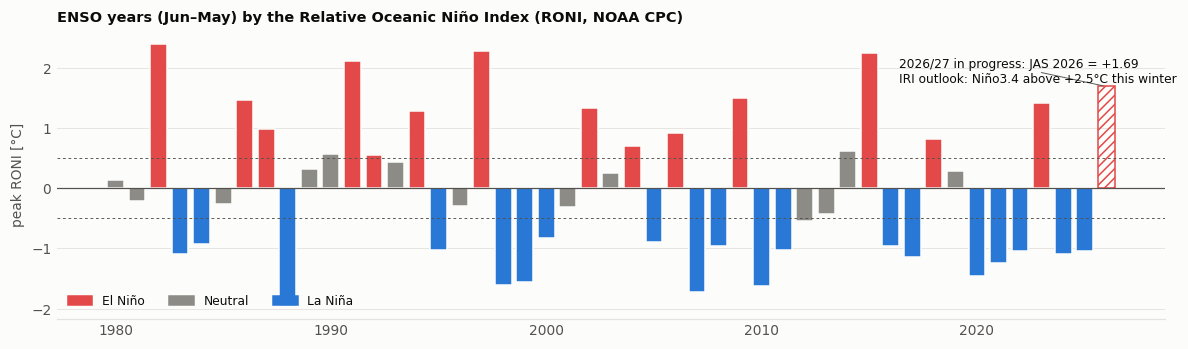

In [2]:
Image(filename="out/0_enso_years.png")

---
## 1. Forecast: winter 2026/27 and summer 2027

**Winter (+3–6 months)** is the El Niño peak, so the canonical impacts for that season apply.
Confidence is high, because an event this strong almost always produces the signal.

**Summer 2027 (+9–12 months)** is the year after the peak. Of the 8 strong El Niños since 1950,
the following year brought La Niña 5 times, Neutral twice, and once El Niño continued.
The map therefore shows the impacts of a **decaying El Niño and a possible La Niña**, with lower confidence.

The numbers next to the cyclone basins are not typed in by hand. They come from part 2 and from
the composite of seasons that followed a strong El Niño.

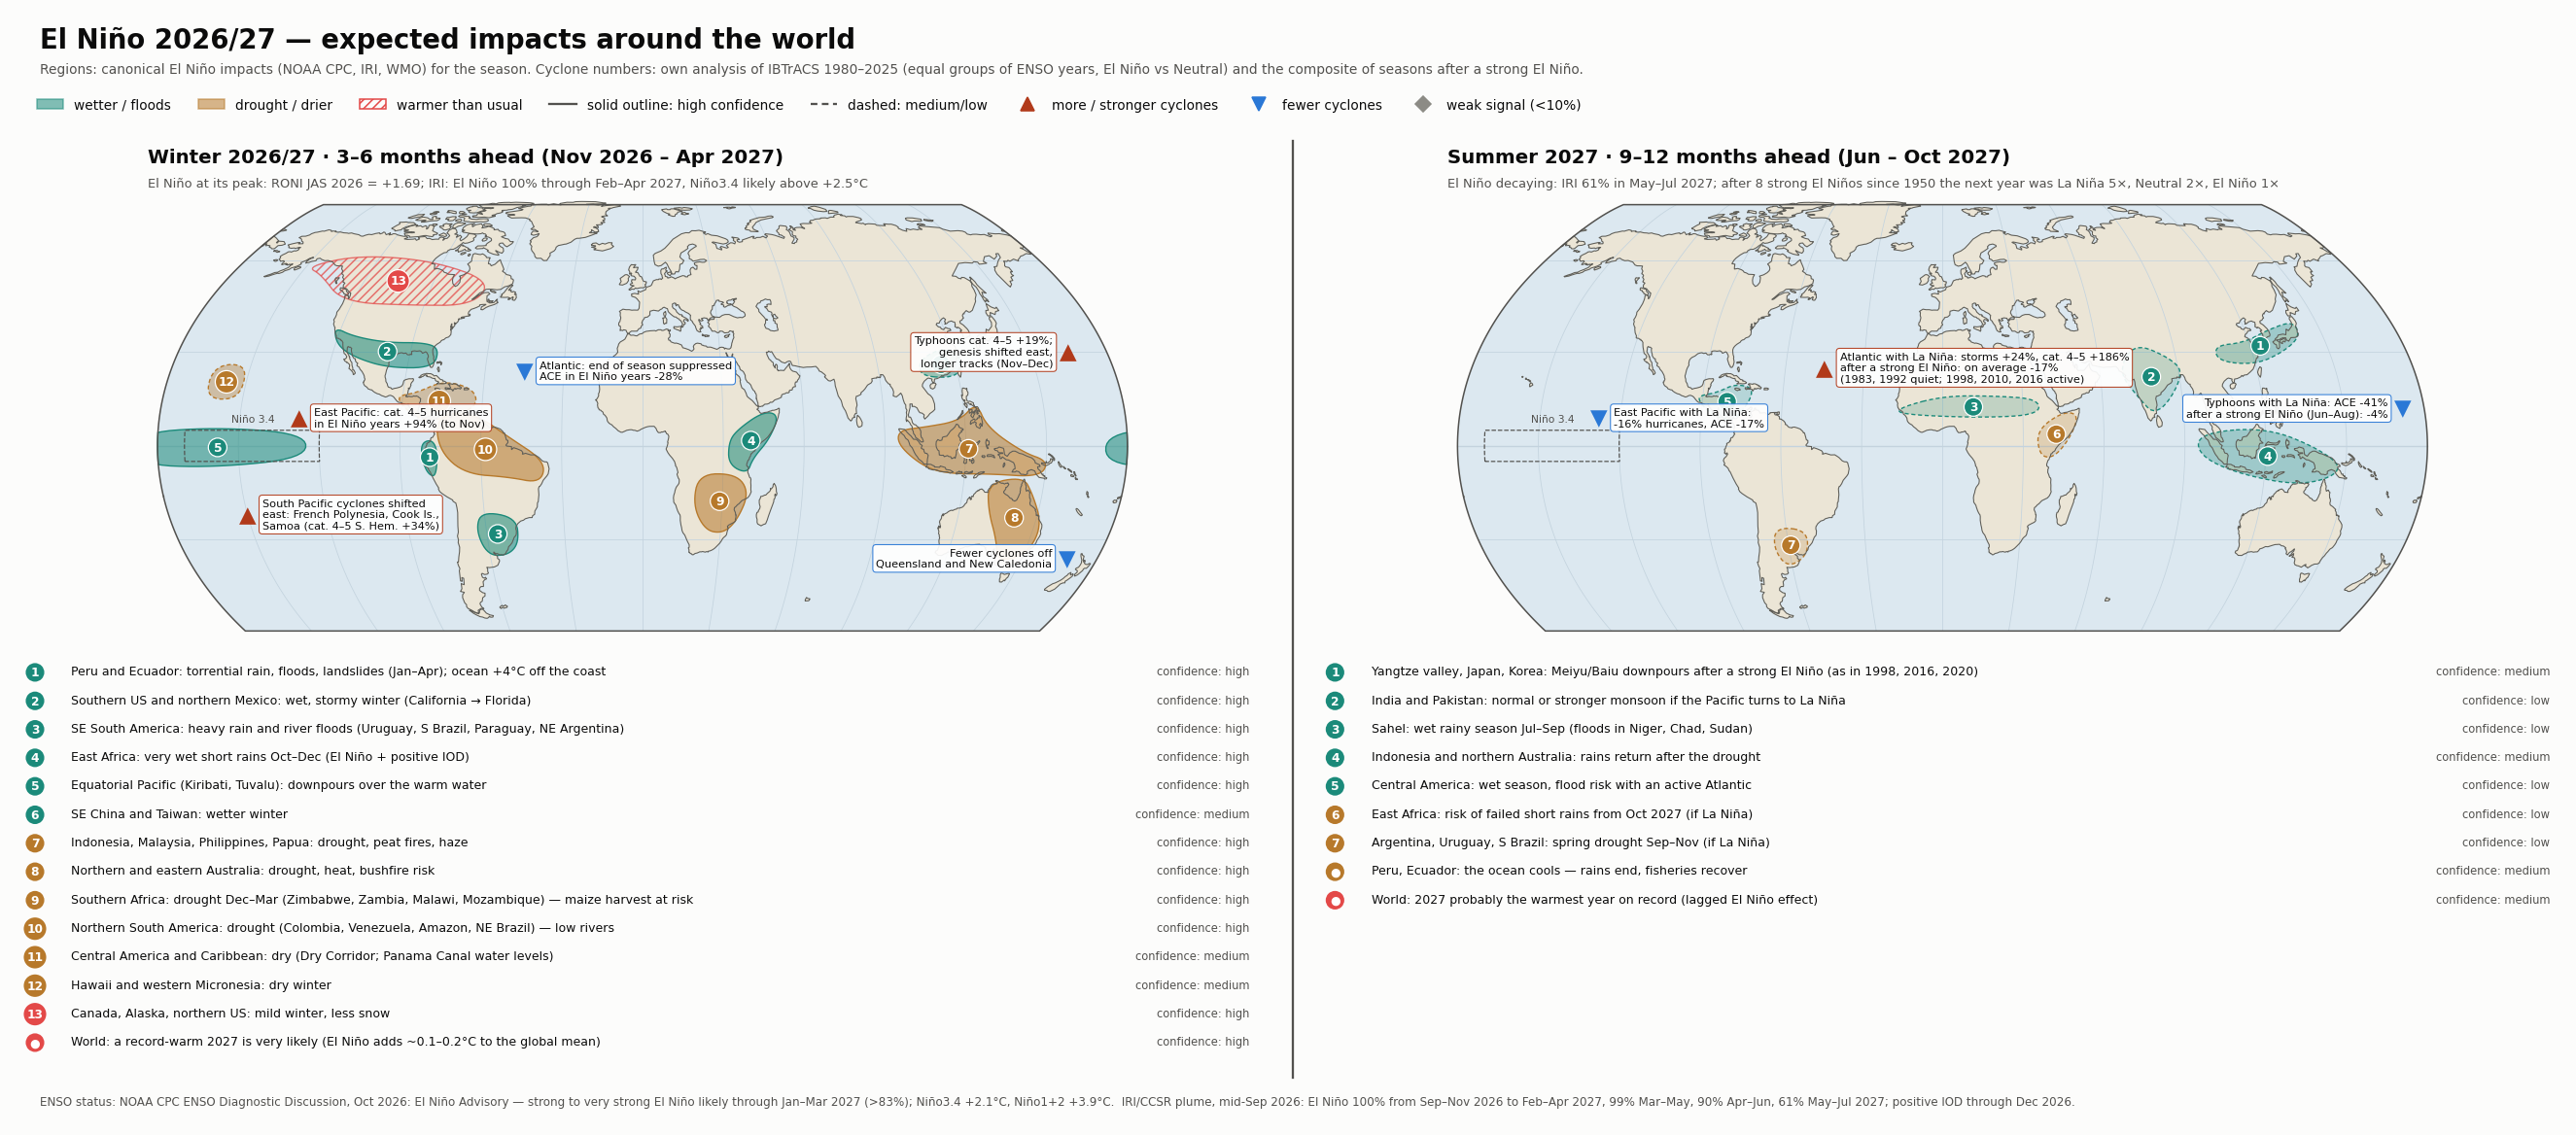

In [3]:
Image(filename="maps/forecast_maps.png")

In [4]:
print("The year after a strong El Niño (peak RONI >= 1.5):")
display(enso.after_strong_el_nino(enso.enso_years()))
print("Cyclone seasons in the year after a strong El Niño vs the 1980–2025 mean (IBTrACS):")
display(pd.read_csv("out/after_strong_el_nino.csv"))

The year after a strong El Niño (peak RONI >= 1.5):


,el_nino,peak,next_label,next_jas,next_phase,next_peak
0,1957/58,1.89,1958/59,0.26,Neutral,0.77
1,1965/66,1.99,1966/67,0.19,Neutral,-0.26
2,1972/73,1.97,1973/74,-1.19,La Niña,-1.91
3,1982/83,2.40,1983/84,-0.23,La Niña,-1.10
4,1991/92,2.12,1992/93,0.30,El Niño,0.55
5,1997/98,2.28,1998/99,-1.14,La Niña,-1.61
6,2009/10,1.50,2010/11,-1.39,La Niña,-1.63
7,2015/16,2.25,2016/17,-0.81,La Niña,-0.96


Cyclone seasons in the year after a strong El Niño vs the 1980–2025 mean (IBTrACS):


,measure,after_strong_EN,mean_1980_2025,difference_pct,seasons
0,Typhoons (W Pacific) Jun–Aug,10.0,10.39,-3.77,1983/84 1992/93 1998/99 2010/11 2016/17
1,Typhoons (W Pacific) whole season,24.0,24.70,-2.82,1983/84 1992/93 1998/99 2010/11 2016/17
2,Atlantic hurricanes,11.4,13.72,-16.89,1983/84 1992/93 1998/99 2010/11 2016/17
3,Atlantic hurricanes cat. 3–5,2.8,2.91,-3.88,1983/84 1992/93 1998/99 2010/11 2016/17
4,East Pacific hurricanes,17.6,17.24,2.09,1983/84 1992/93 1998/99 2010/11 2016/17
5,North Indian cyclones,5.8,4.96,17.02,1983/84 1992/93 1998/99 2010/11 2016/17


---
## 2. GDACS analysis: El Niño vs normal circulation vs La Niña

**Rule:** three groups with **the same number of years** (n = size of the smallest phase within
the window in which GDACS has that event type). From the larger phases we take the clearest years:
El Niño and La Niña with the largest anomaly, Neutral with the smallest.
Each bar is the group mean; the dots are individual years.

`p` is a two-sided permutation test of El Niño vs La Niña over **all** years in the window.
A star ✱ marks p < 0.05.

| GDACS type | continuous since | notes |
|---|---|---|
| cyclones (TC) | Jul 2011, so the first full year is 2012/13 | 14 seasons, **n = 3 per phase** |
| floods (FL) | 2000 | three catalogues: DFO (to 2015), JRC (2016–18, fragmentary), GloFAS (from 2019, ~4× more events). 2016–18 are dropped; each phase gets the same number of DFO and GloFAS years; regions are counted as **% of all floods** in that year |
| droughts (DR) | Jun 2018 | only 8 years, one of them Neutral, so the comparison uses **months** with an active drought (ENSO phase 3 months earlier) |

### 2.1 Monsoons

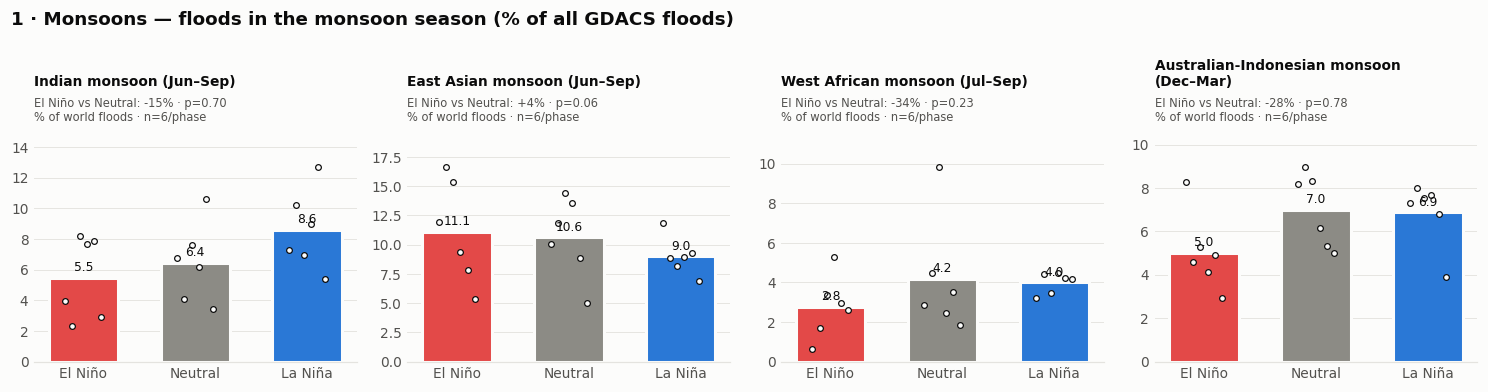

In [5]:
Image(filename="out/1_monsoons.png")

In [6]:
show(cmp_, 'Monsoons', 'GDACS')

,period,n per phase,El Niño,Neutral,La Niña,El Niño vs Neutral [%],La Niña vs Neutral [%],"p (EN vs LN, all years)"
measure,,,,,,,,
Indian monsoon (Jun–Sep),2000/01–2025/26 excl. 2016–18,6,5.47,6.44,8.60,-14.93,33.57,0.70
East Asian monsoon (Jun–Sep),2000/01–2025/26 excl. 2016–18,6,11.10,10.63,9.01,4.38,-15.24,0.06
West African monsoon (Jul–Sep),2000/01–2025/26 excl. 2016–18,6,2.76,4.18,4.00,-33.90,-4.24,0.23
Australian-Indonesian monsoon (Dec–Mar),2000/01–2025/26 excl. 2016–18,6,5.02,7.00,6.88,-28.32,-1.76,0.78


### 2.2 Hurricanes

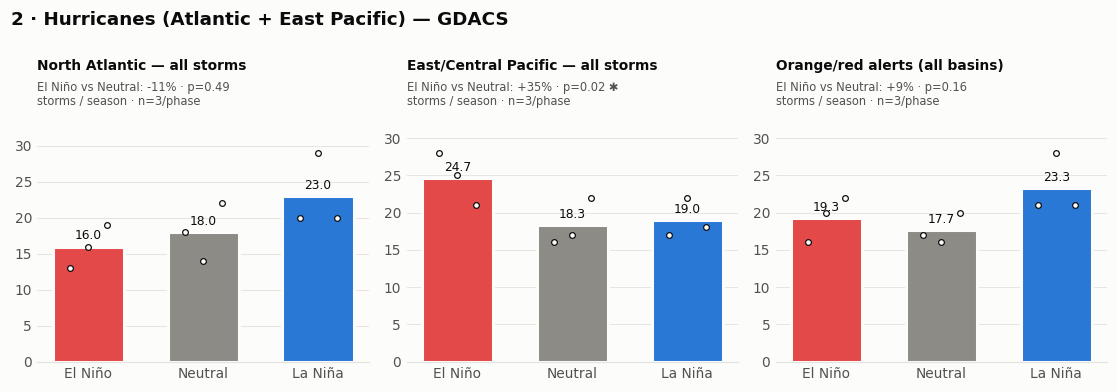

In [7]:
Image(filename="out/2_hurricanes.png")

In [8]:
show(cmp_, 'Hurricanes', 'GDACS')

,period,n per phase,El Niño,Neutral,La Niña,El Niño vs Neutral [%],La Niña vs Neutral [%],"p (EN vs LN, all years)"
measure,,,,,,,,
North Atlantic — all storms,2012/13–2025/26,3,16.00,18.00,23.00,-11.11,27.78,0.49
East/Central Pacific — all storms,2012/13–2025/26,3,24.67,18.33,19.00,34.55,3.64,0.02
Orange/red alerts (all basins),2012/13–2025/26,3,19.33,17.67,23.33,9.43,32.08,0.16


### 2.3 Typhoons and other cyclones

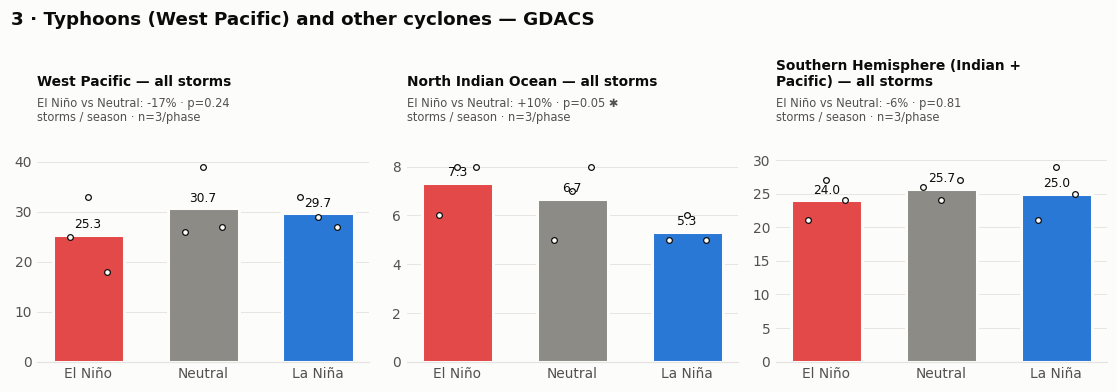

In [9]:
Image(filename="out/3_typhoons_cyclones.png")

In [10]:
show(cmp_, ['Typhoons', 'Cyclones'], 'GDACS')

,period,n per phase,El Niño,Neutral,La Niña,El Niño vs Neutral [%],La Niña vs Neutral [%],"p (EN vs LN, all years)"
measure,,,,,,,,
West Pacific — all storms,2012/13–2025/26,3,25.33,30.67,29.67,-17.39,-3.26,0.24
North Indian Ocean — all storms,2012/13–2025/26,3,7.33,6.67,5.33,10.00,-20.00,0.05
Southern Hemisphere (Indian + Pacific) — all storms,2012/13–2025/26,3,24.00,25.67,25.00,-6.49,-2.60,0.81


### 2.4 Meteorological categories (Saffir-Simpson)

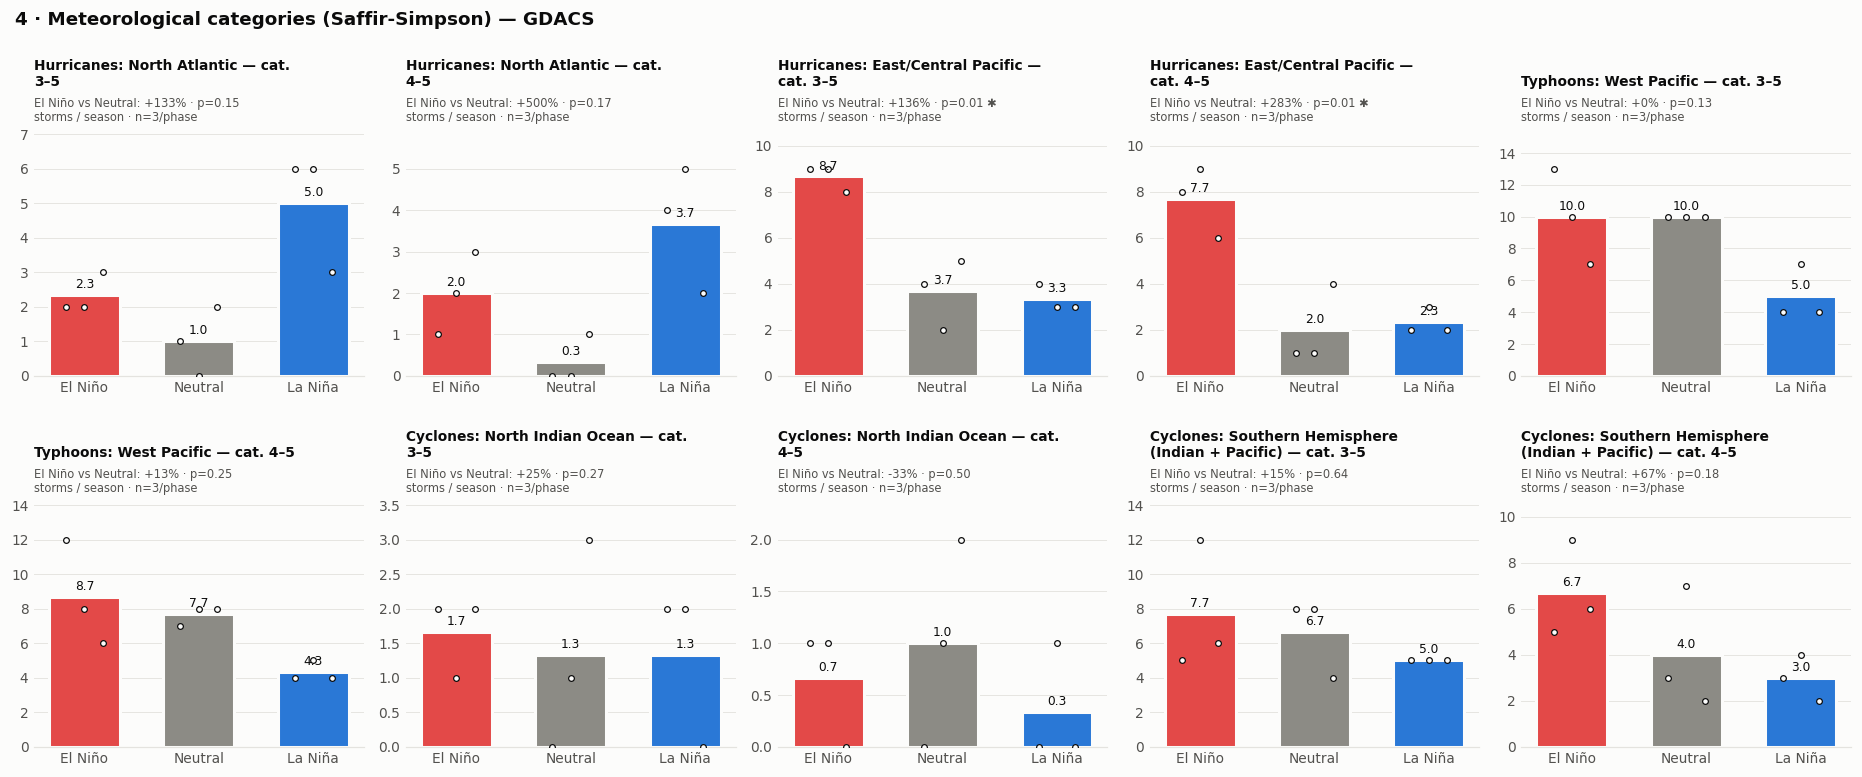

In [11]:
Image(filename="out/4_categories.png")

In [12]:
show(cmp_, 'Categories (Saffir-Simpson)', 'GDACS')

,period,n per phase,El Niño,Neutral,La Niña,El Niño vs Neutral [%],La Niña vs Neutral [%],"p (EN vs LN, all years)"
measure,,,,,,,,
Hurricanes: North Atlantic — cat. 3–5,2012/13–2025/26,3,2.33,1.00,5.00,133.33,400.00,0.15
Hurricanes: North Atlantic — cat. 4–5,2012/13–2025/26,3,2.00,0.33,3.67,500.00,1000.00,0.17
Hurricanes: East/Central Pacific — cat. 3–5,2012/13–2025/26,3,8.67,3.67,3.33,136.36,-9.09,0.01
Hurricanes: East/Central Pacific — cat. 4–5,2012/13–2025/26,3,7.67,2.00,2.33,283.33,16.67,0.01
Typhoons: West Pacific — cat. 3–5,2012/13–2025/26,3,10.00,10.00,5.00,0.00,-50.00,0.13
Typhoons: West Pacific — cat. 4–5,2012/13–2025/26,3,8.67,7.67,4.33,13.04,-43.48,0.25
Cyclones: North Indian Ocean — cat. 3–5,2012/13–2025/26,3,1.67,1.33,1.33,25.00,0.00,0.27
Cyclones: North Indian Ocean — cat. 4–5,2012/13–2025/26,3,0.67,1.00,0.33,-33.33,-66.67,0.50
Cyclones: Southern Hemisphere (Indian + Pacific) — cat. 3–5,2012/13–2025/26,3,7.67,6.67,5.00,15.00,-25.00,0.64


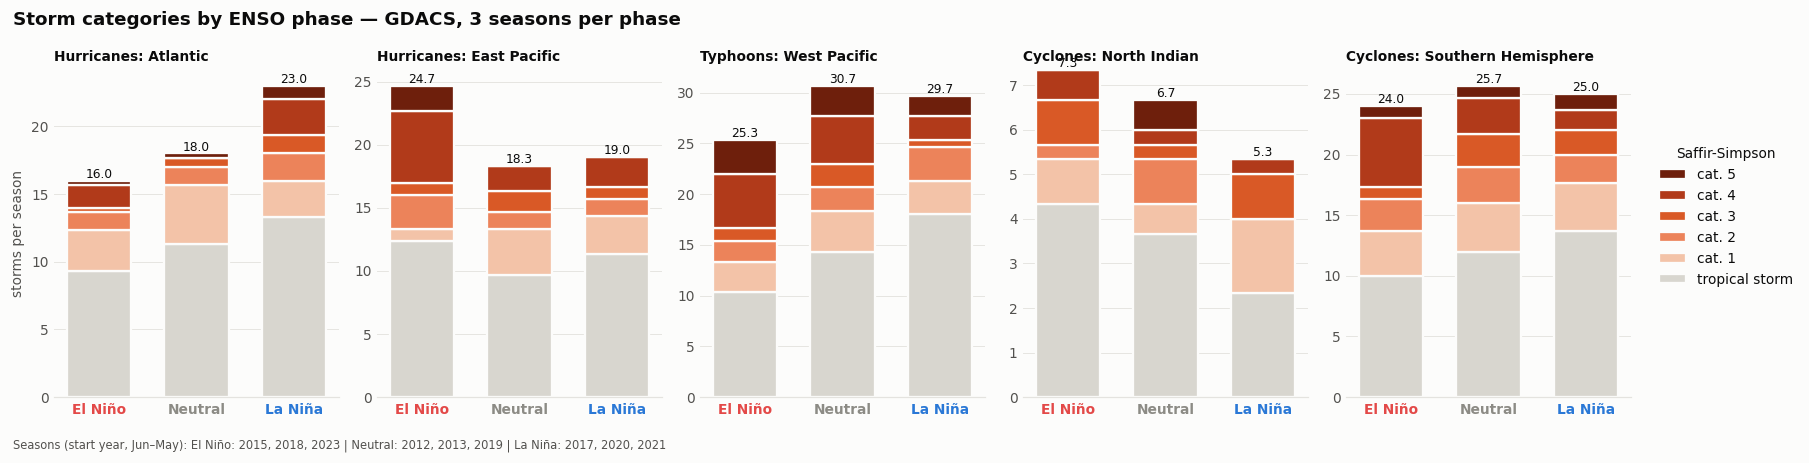

In [13]:
Image(filename="out/4b_category_mix_gdacs.png")

### 2.5 Heavy rain and floods

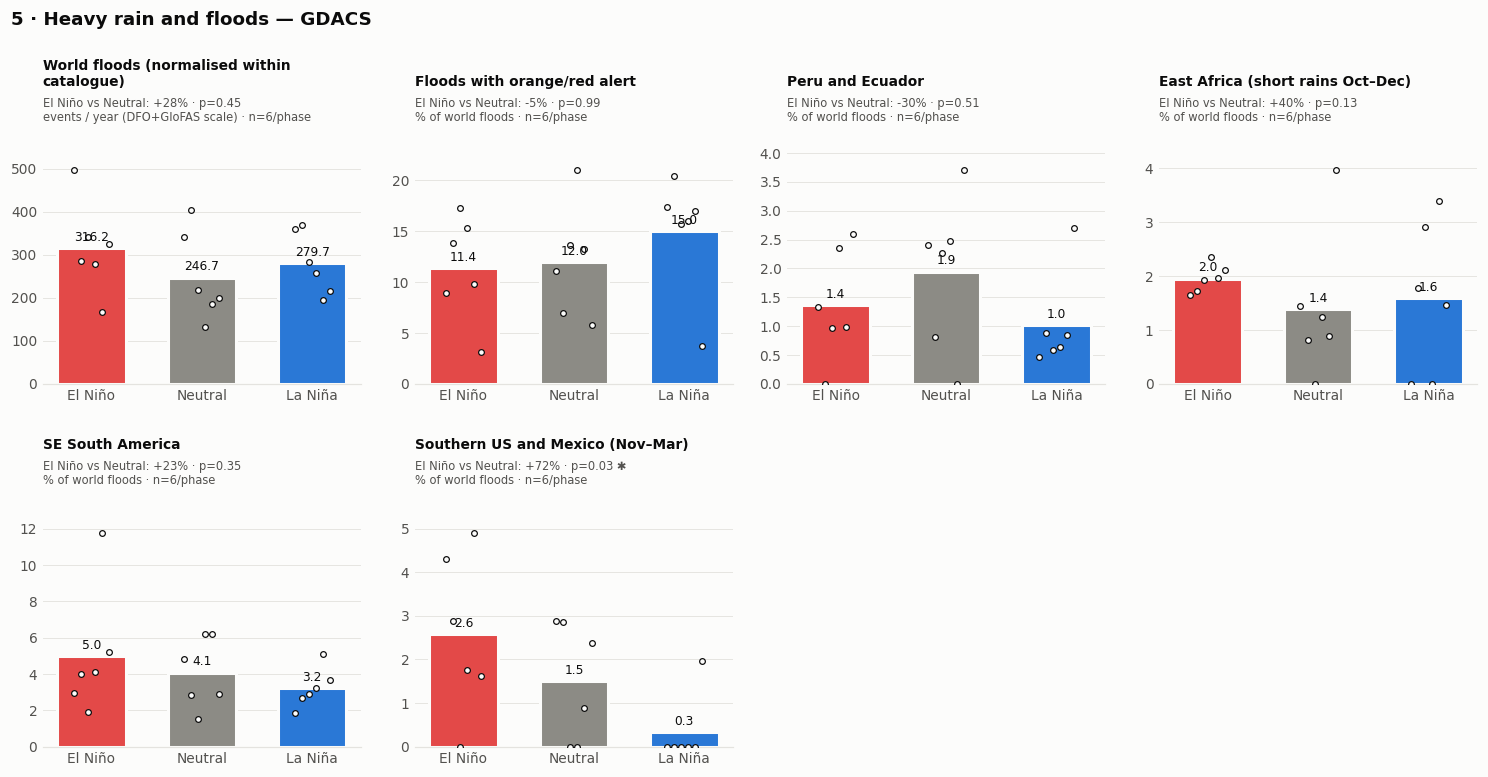

In [14]:
Image(filename="out/5_heavy_rain.png")

In [15]:
show(cmp_, 'Heavy rain', 'GDACS')

,period,n per phase,El Niño,Neutral,La Niña,El Niño vs Neutral [%],La Niña vs Neutral [%],"p (EN vs LN, all years)"
measure,,,,,,,,
World floods (normalised within catalogue),2000/01–2025/26 excl. 2016–18,6,316.17,246.66,279.70,28.18,13.40,0.45
Floods with orange/red alert,2000/01–2025/26 excl. 2016–18,6,11.37,11.95,15.02,-4.88,25.70,0.99
Peru and Ecuador,2000/01–2025/26 excl. 2016–18,6,1.37,1.94,1.02,-29.60,-47.61,0.51
East Africa (short rains Oct–Dec),2000/01–2025/26 excl. 2016–18,6,1.95,1.39,1.59,40.46,14.36,0.13
SE South America,2000/01–2025/26 excl. 2016–18,6,5.00,4.08,3.23,22.64,-20.82,0.35
Southern US and Mexico (Nov–Mar),2000/01–2025/26 excl. 2016–18,6,2.58,1.50,0.33,71.69,-78.23,0.03


### 2.6 Droughts

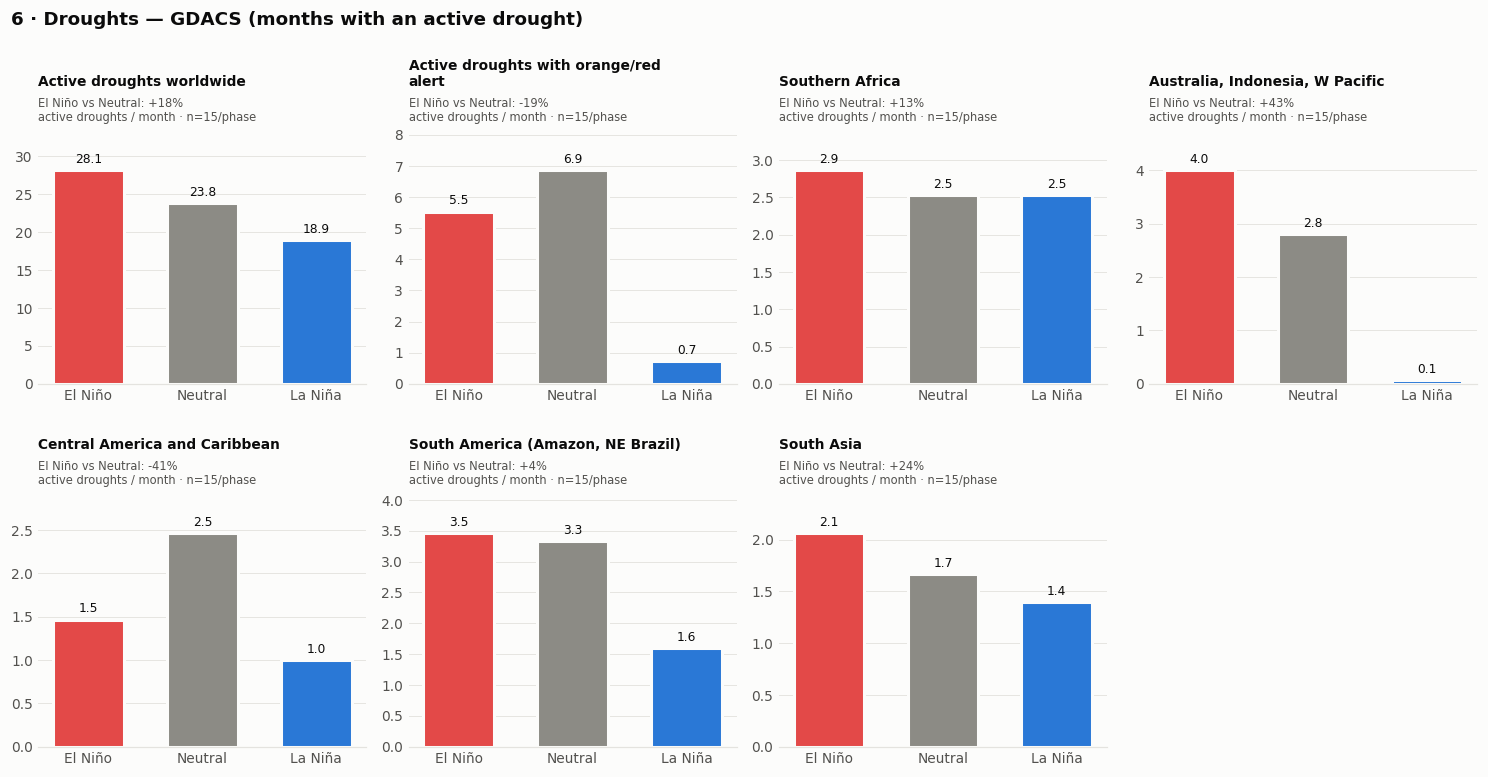

In [16]:
Image(filename="out/6_droughts.png")

In [17]:
show(cmp_, 'Droughts', 'GDACS')

,period,n per phase,El Niño,Neutral,La Niña,El Niño vs Neutral [%],La Niña vs Neutral [%],"p (EN vs LN, all years)"
measure,,,,,,,,
Active droughts worldwide,"2018-06–2026-09 (months, ENSO phase −3 mo.)",15,28.13,23.80,18.87,18.21,-20.73,—
Active droughts with orange/red alert,"2018-06–2026-09 (months, ENSO phase −3 mo.)",15,5.53,6.87,0.73,-19.42,-89.32,—
Southern Africa,"2018-06–2026-09 (months, ENSO phase −3 mo.)",15,2.87,2.53,2.53,13.16,0.00,—
"Australia, Indonesia, W Pacific","2018-06–2026-09 (months, ENSO phase −3 mo.)",15,4.00,2.80,0.07,42.86,-97.62,—
Central America and Caribbean,"2018-06–2026-09 (months, ENSO phase −3 mo.)",15,1.47,2.47,1.00,-40.54,-59.46,—
"South America (Amazon, NE Brazil)","2018-06–2026-09 (months, ENSO phase −3 mo.)",15,3.47,3.33,1.60,4.00,-52.00,—
South Asia,"2018-06–2026-09 (months, ENSO phase −3 mo.)",15,2.07,1.67,1.40,24.00,-16.00,—


### 2.7 Long-record check (IBTrACS 1980–2025, n = 13 per phase)

GDACS gives only 3 cyclone seasons per phase, so the same test is repeated on 46 IBTrACS seasons,
with the same basin definition and the same wind scale (1-minute).
**ACE**, the accumulated cyclone energy of a season, is added as well.

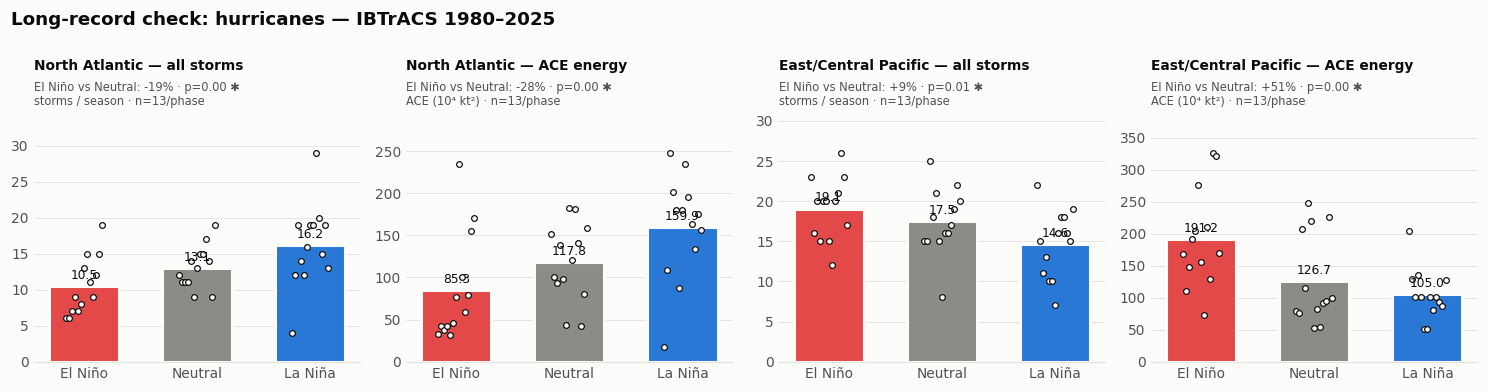

In [18]:
Image(filename="out/7_ibtracs_hurricanes.png")

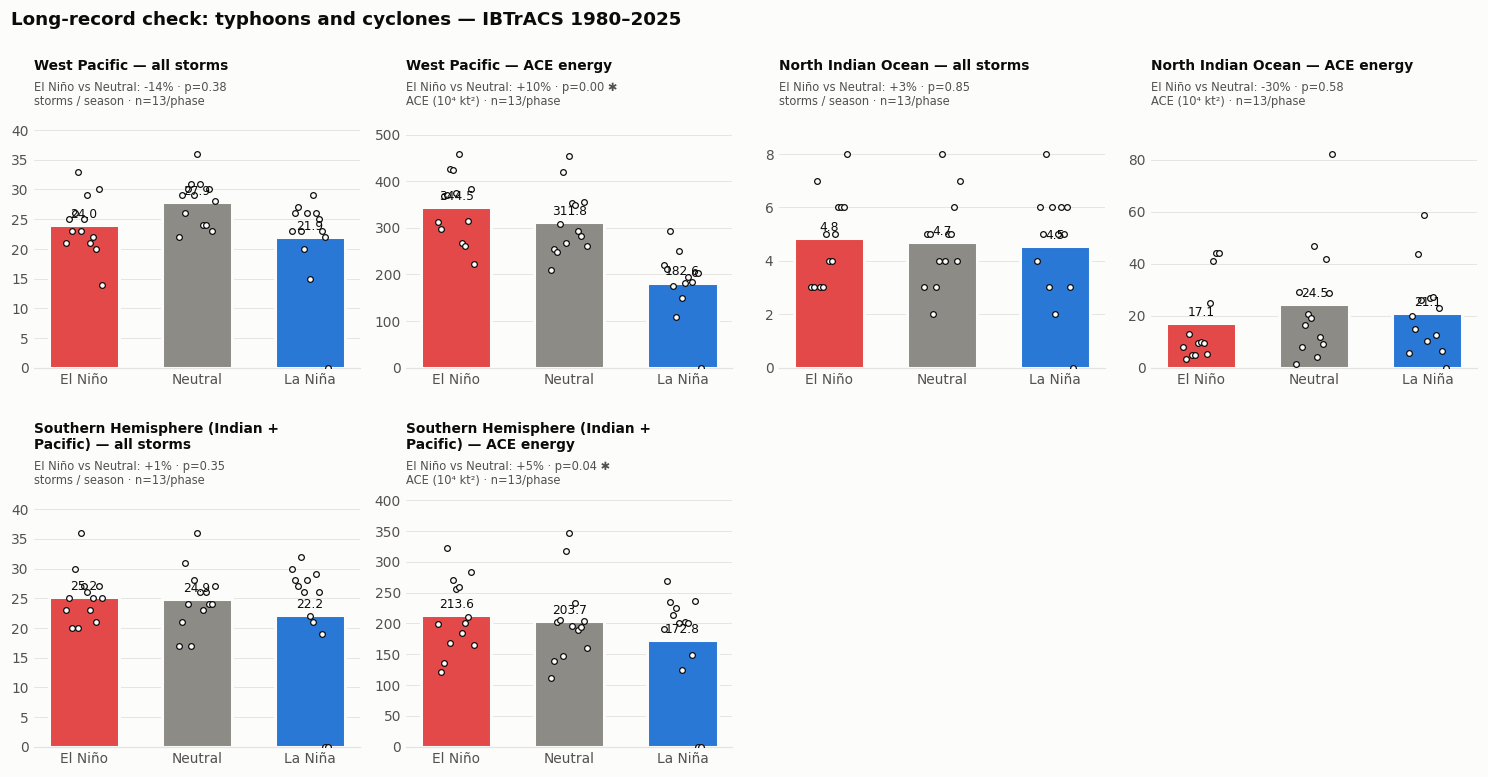

In [19]:
Image(filename="out/8_ibtracs_typhoons_cyclones.png")

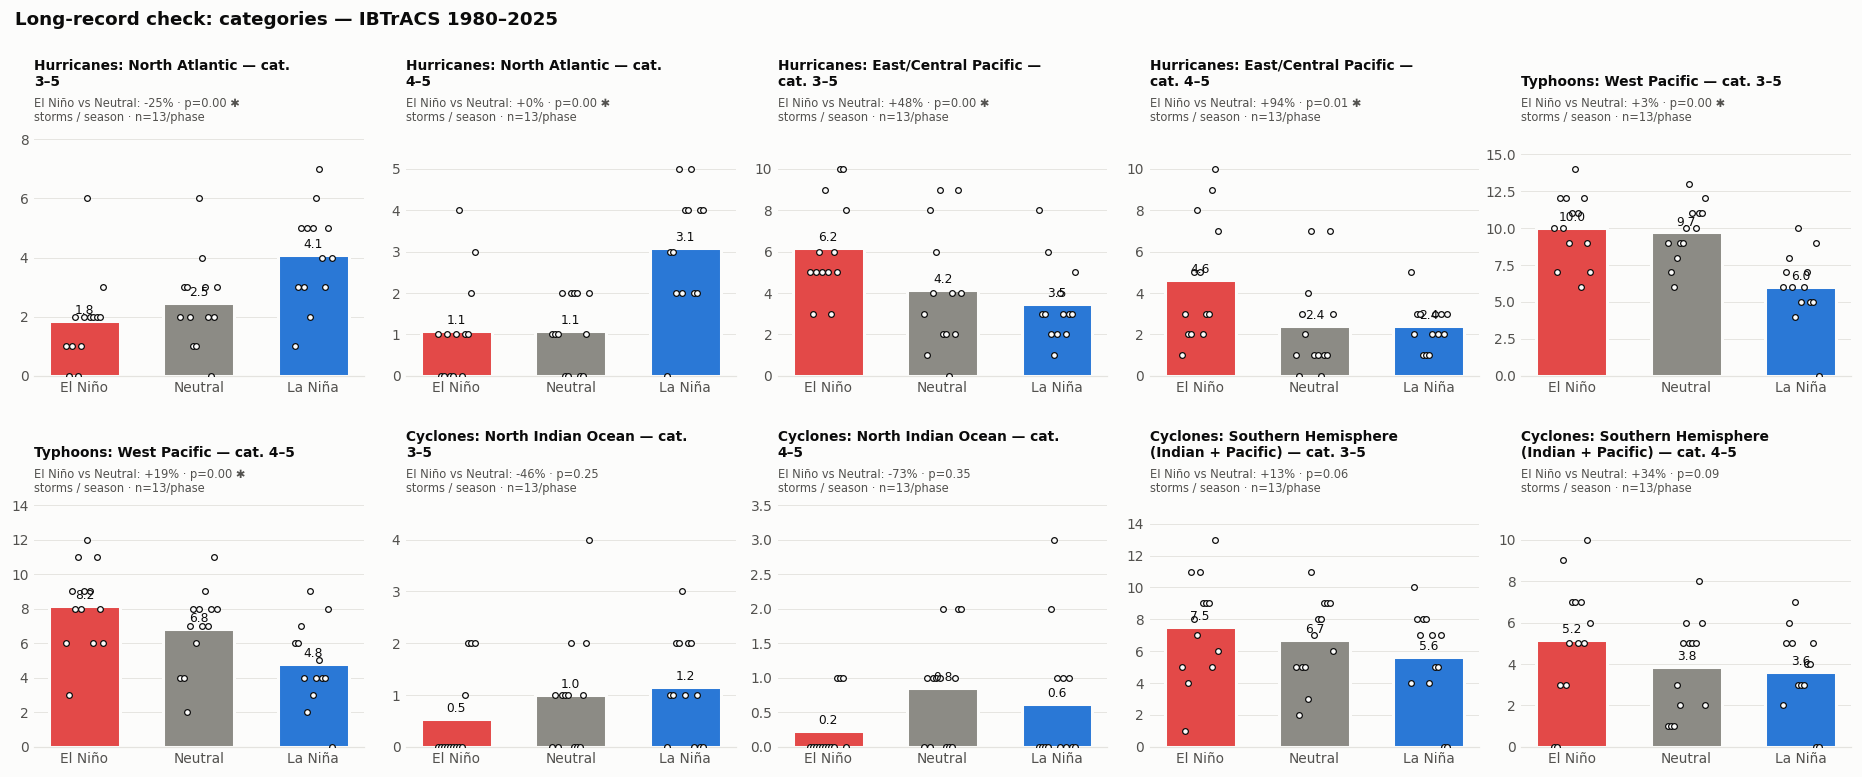

In [20]:
Image(filename="out/9_ibtracs_categories.png")

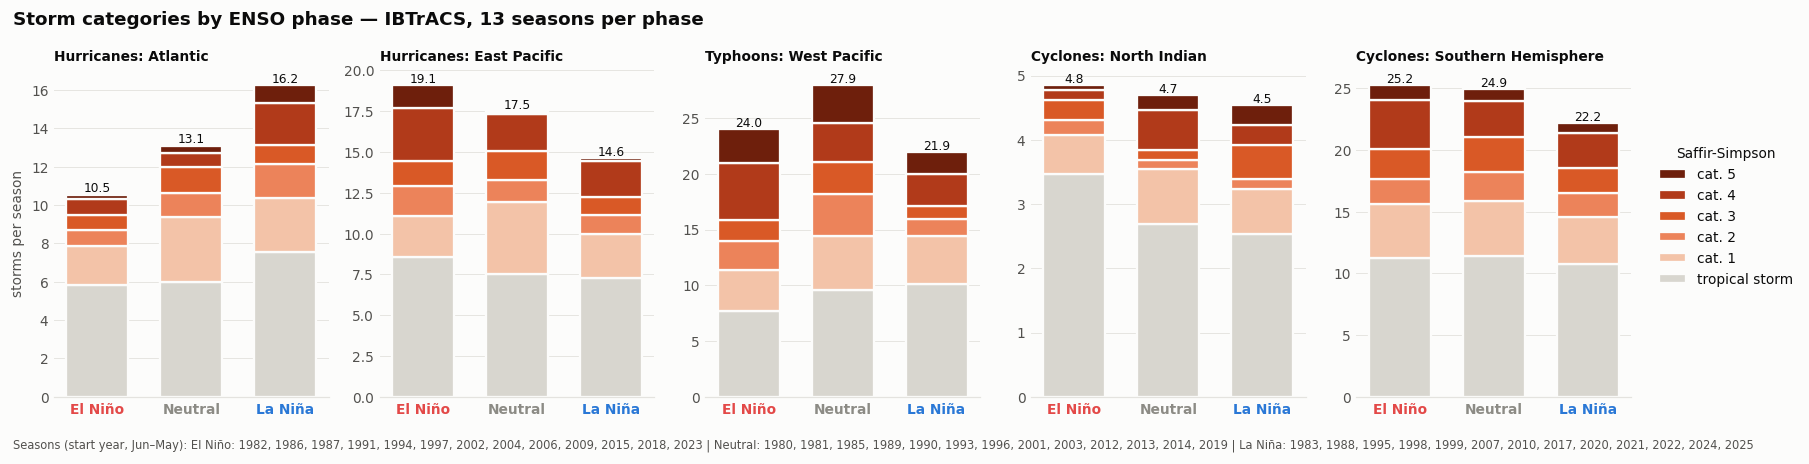

In [21]:
Image(filename="out/9b_category_mix_ibtracs.png")

In [22]:
show(cmp_, ['Hurricanes', 'Typhoons', 'Cyclones', 'Categories (Saffir-Simpson)'], 'IBTrACS')

,period,n per phase,El Niño,Neutral,La Niña,El Niño vs Neutral [%],La Niña vs Neutral [%],"p (EN vs LN, all years)"
measure,,,,,,,,
North Atlantic — all storms,1980/81–2025/26,13,10.54,13.08,16.23,-19.41,24.12,0.00
Hurricanes: North Atlantic — cat. 3–5,1980/81–2025/26,13,1.85,2.46,4.08,-25.00,65.62,0.00
Hurricanes: North Atlantic — cat. 4–5,1980/81–2025/26,13,1.08,1.08,3.08,0.00,185.71,0.00
North Atlantic — ACE energy,1980/81–2025/26,13,85.30,117.81,159.87,-27.59,35.70,0.00
East/Central Pacific — all storms,1980/81–2025/26,13,19.08,17.46,14.62,9.25,-16.30,0.01
Hurricanes: East/Central Pacific — cat. 3–5,1980/81–2025/26,13,6.15,4.15,3.46,48.15,-16.67,0.00
Hurricanes: East/Central Pacific — cat. 4–5,1980/81–2025/26,13,4.62,2.38,2.38,93.55,0.00,0.01
East/Central Pacific — ACE energy,1980/81–2025/26,13,191.22,126.67,105.02,50.96,-17.09,0.00
West Pacific — all storms,1980/81–2025/26,13,24.00,27.92,21.92,-14.05,-21.49,0.38


---
## 3. Hazard maps on a long record

One image per hazard, three hex maps each: theory, El Niño minus Neutral, La Niña minus Neutral.
The Neutral benchmark is the zero line of maps 2–3, not a map of its own.
**Red = more of the hazard, green = less.** Hexagons are translucent so the continents show through.
A bold number with * marks a hexagon that differs from the Neutral benchmark at p < 0.10
(Welch t-test over the years of the two groups). Hazards are classified from raw measurements:

| hazard | data | classification |
|---|---|---|
| tropical cyclones | IBTrACS 6-hourly wind, 1980– | days with wind ≥ 34 kt in the hexagon |
| major cyclones | IBTrACS 6-hourly wind, 1980– | days with wind ≥ 96 kt (cat. 3–5) |
| drought | GPCP v2.3 monthly rain, 1979– | months with 6-month SPI ≤ −1.0 (non-parametric SPI) |
| monsoon drought | GPCP v2.3, monsoon domains | local-summer rainfall deficit, % below normal |
| heatwaves | GHCN-CAMS 2 m temperature, 1950– | months above the 90th percentile of the **detrended** anomaly |

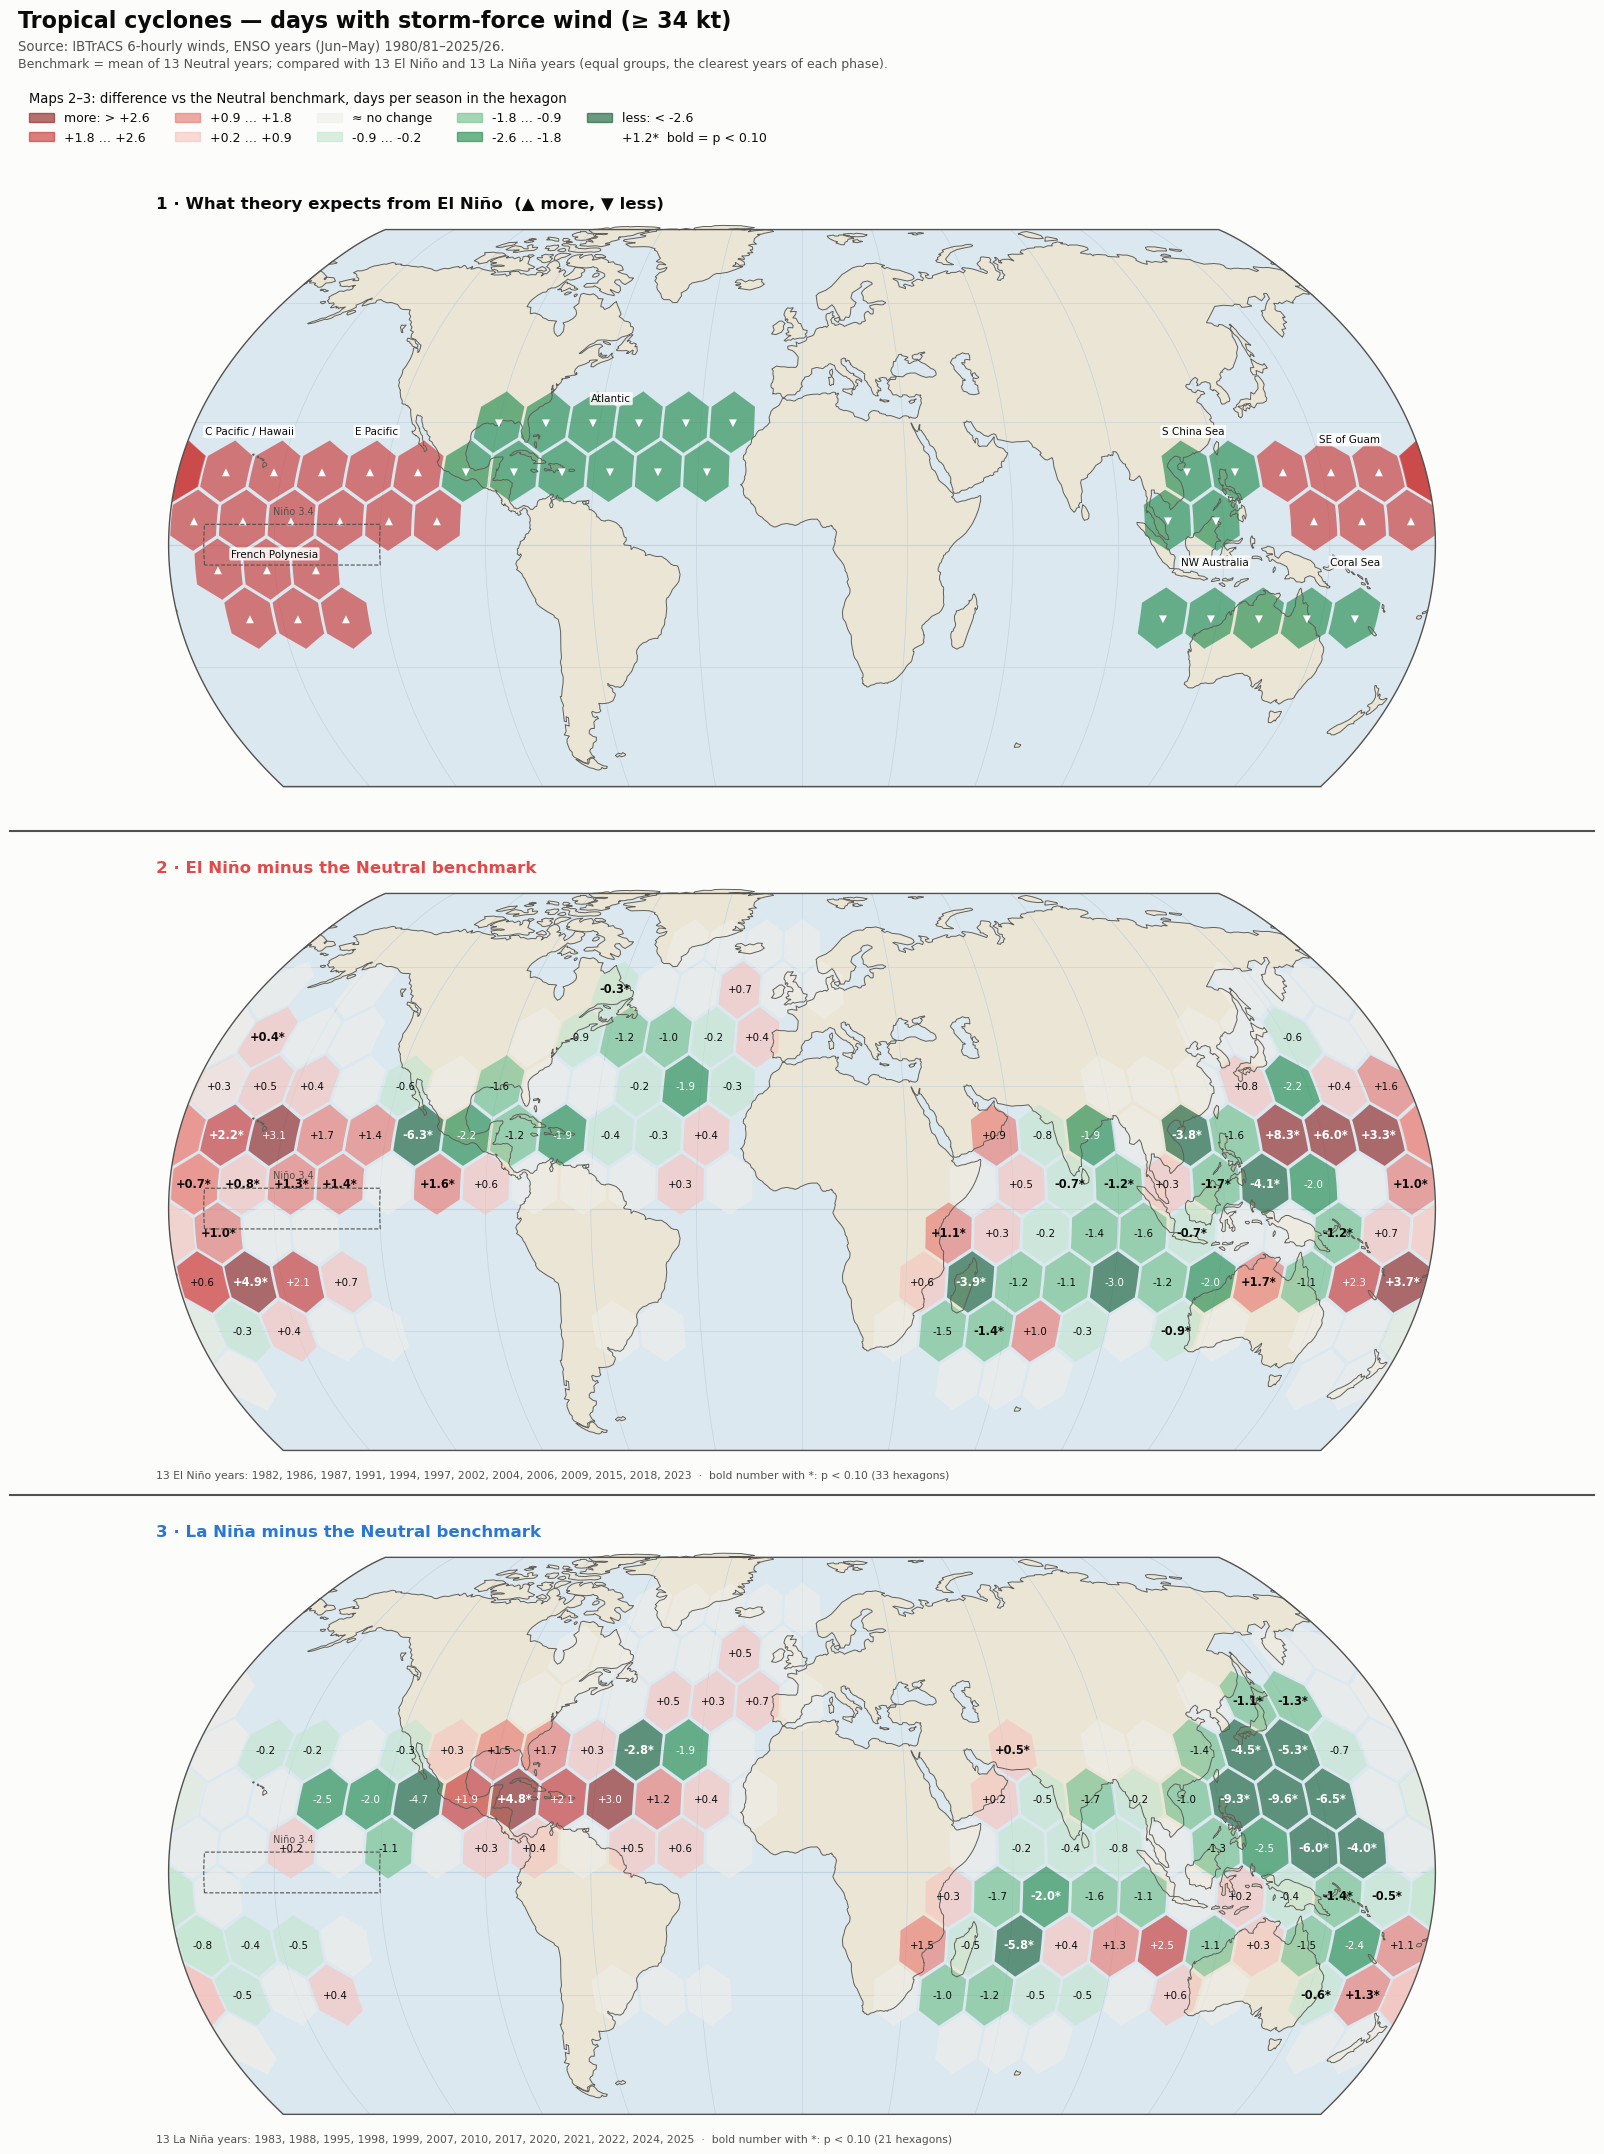

In [23]:
Image(filename="maps/hex_1_cyclones.png")

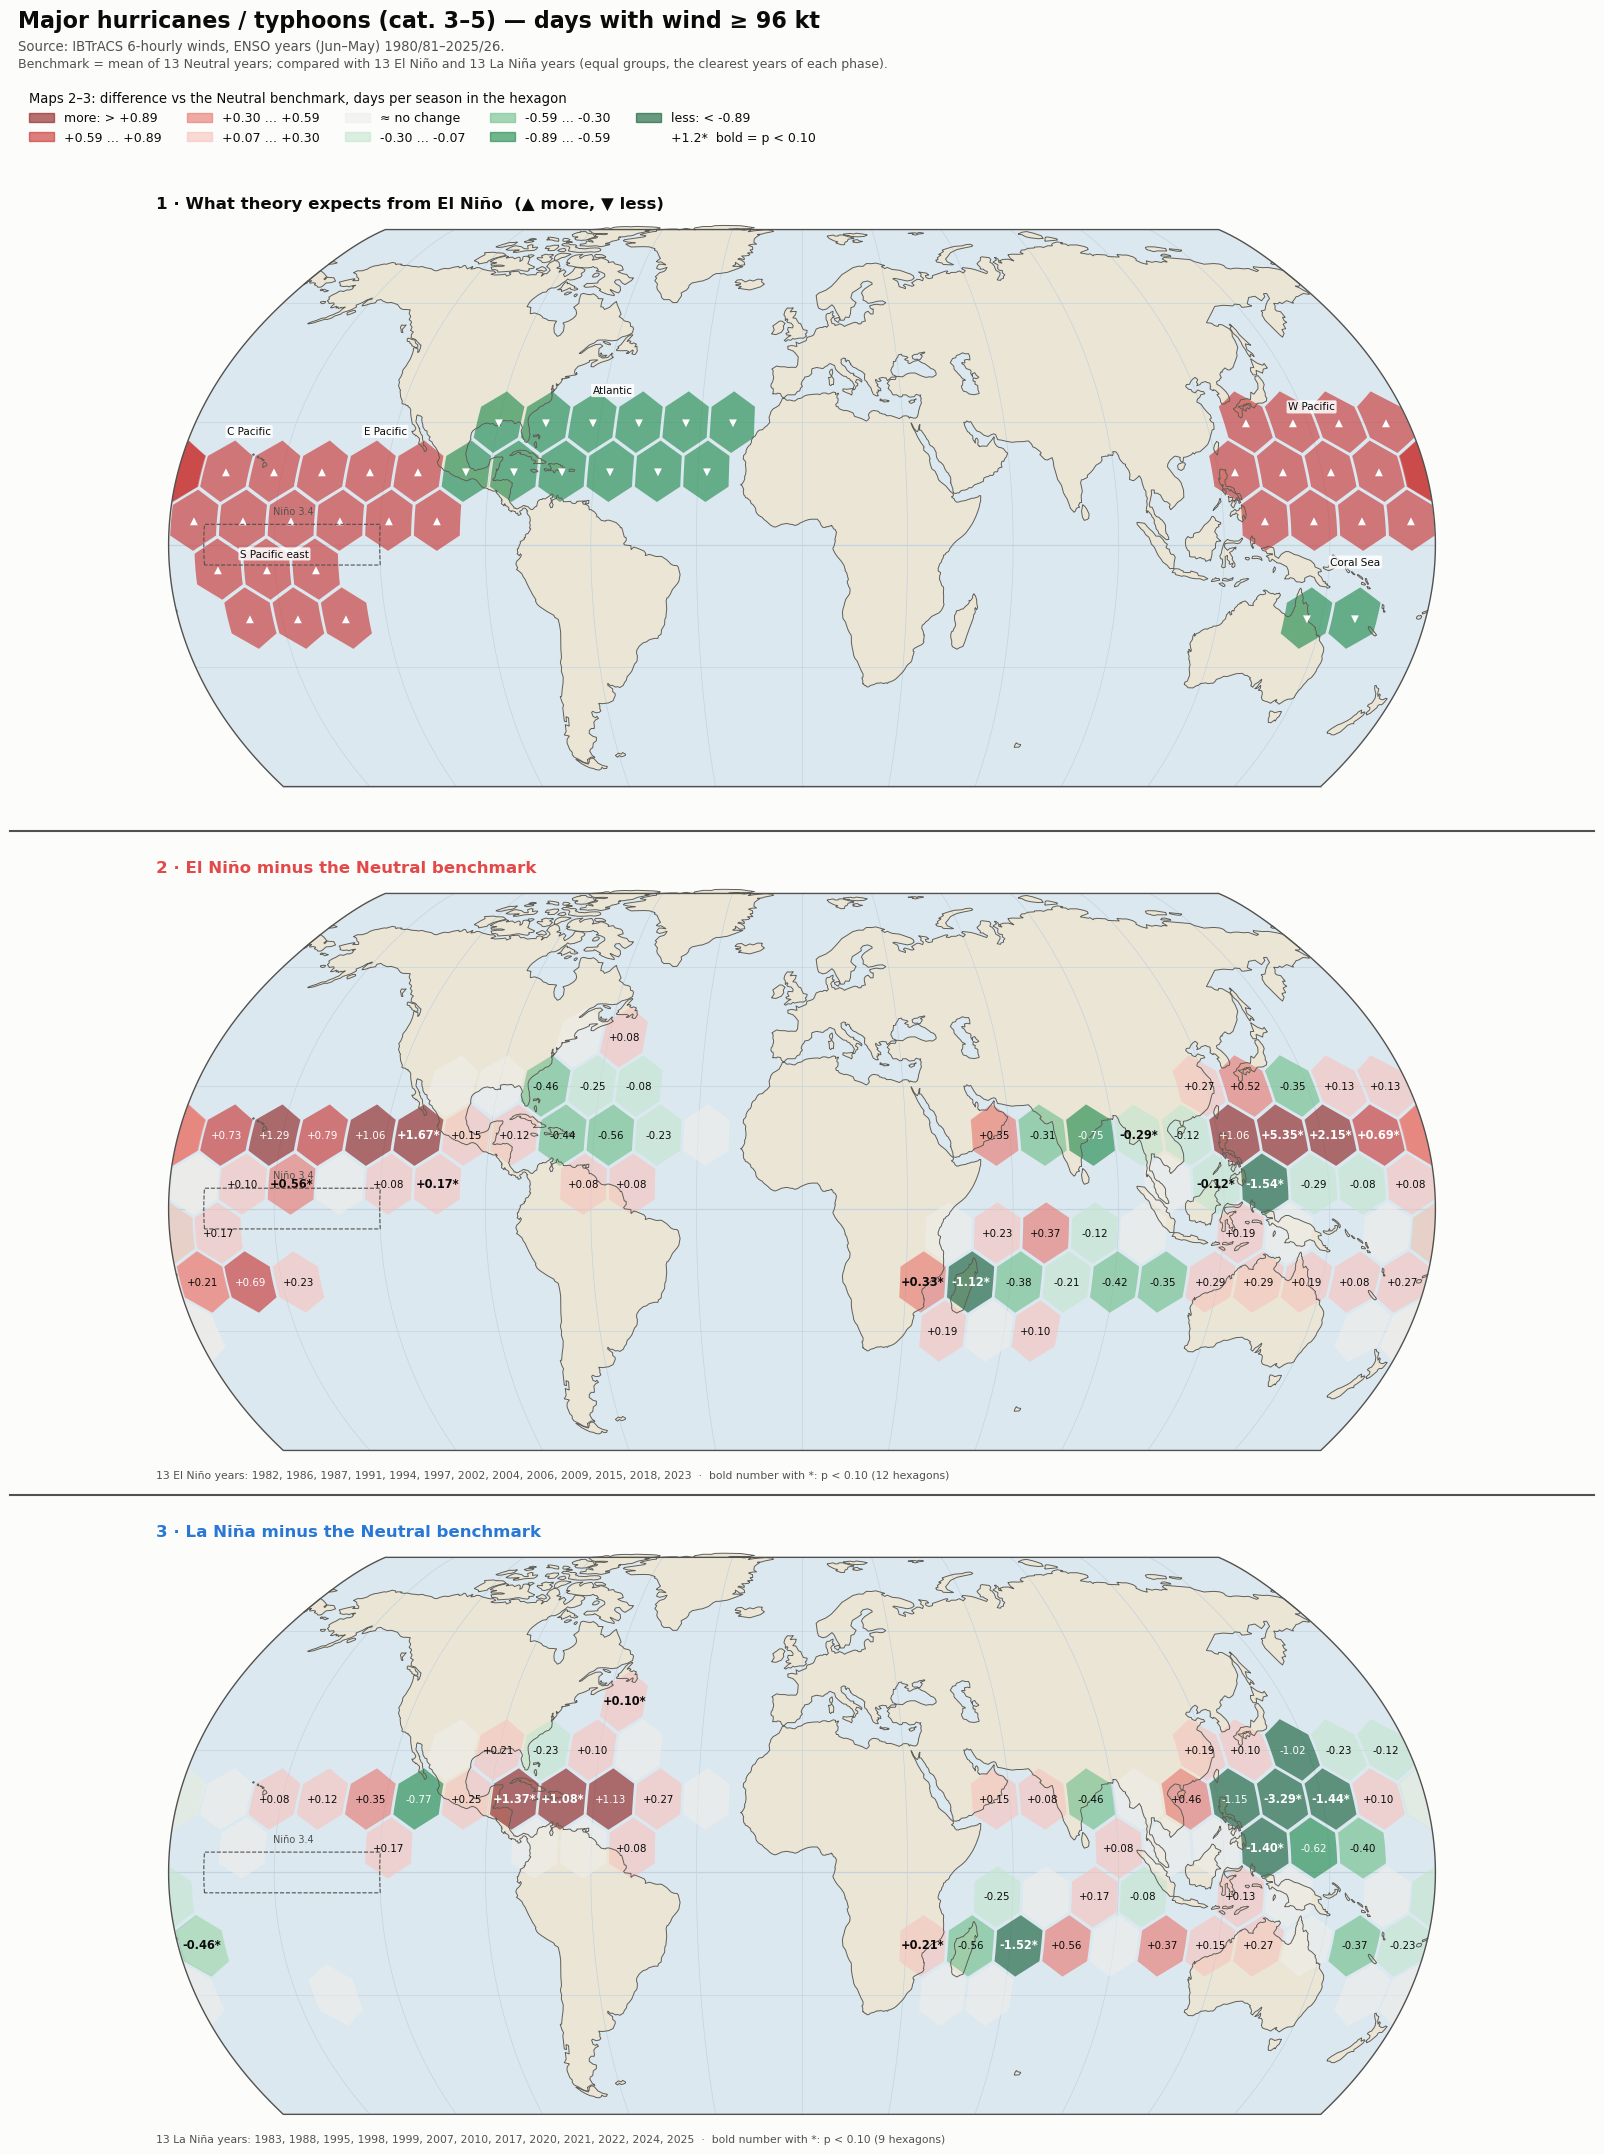

In [24]:
Image(filename="maps/hex_2_major.png")

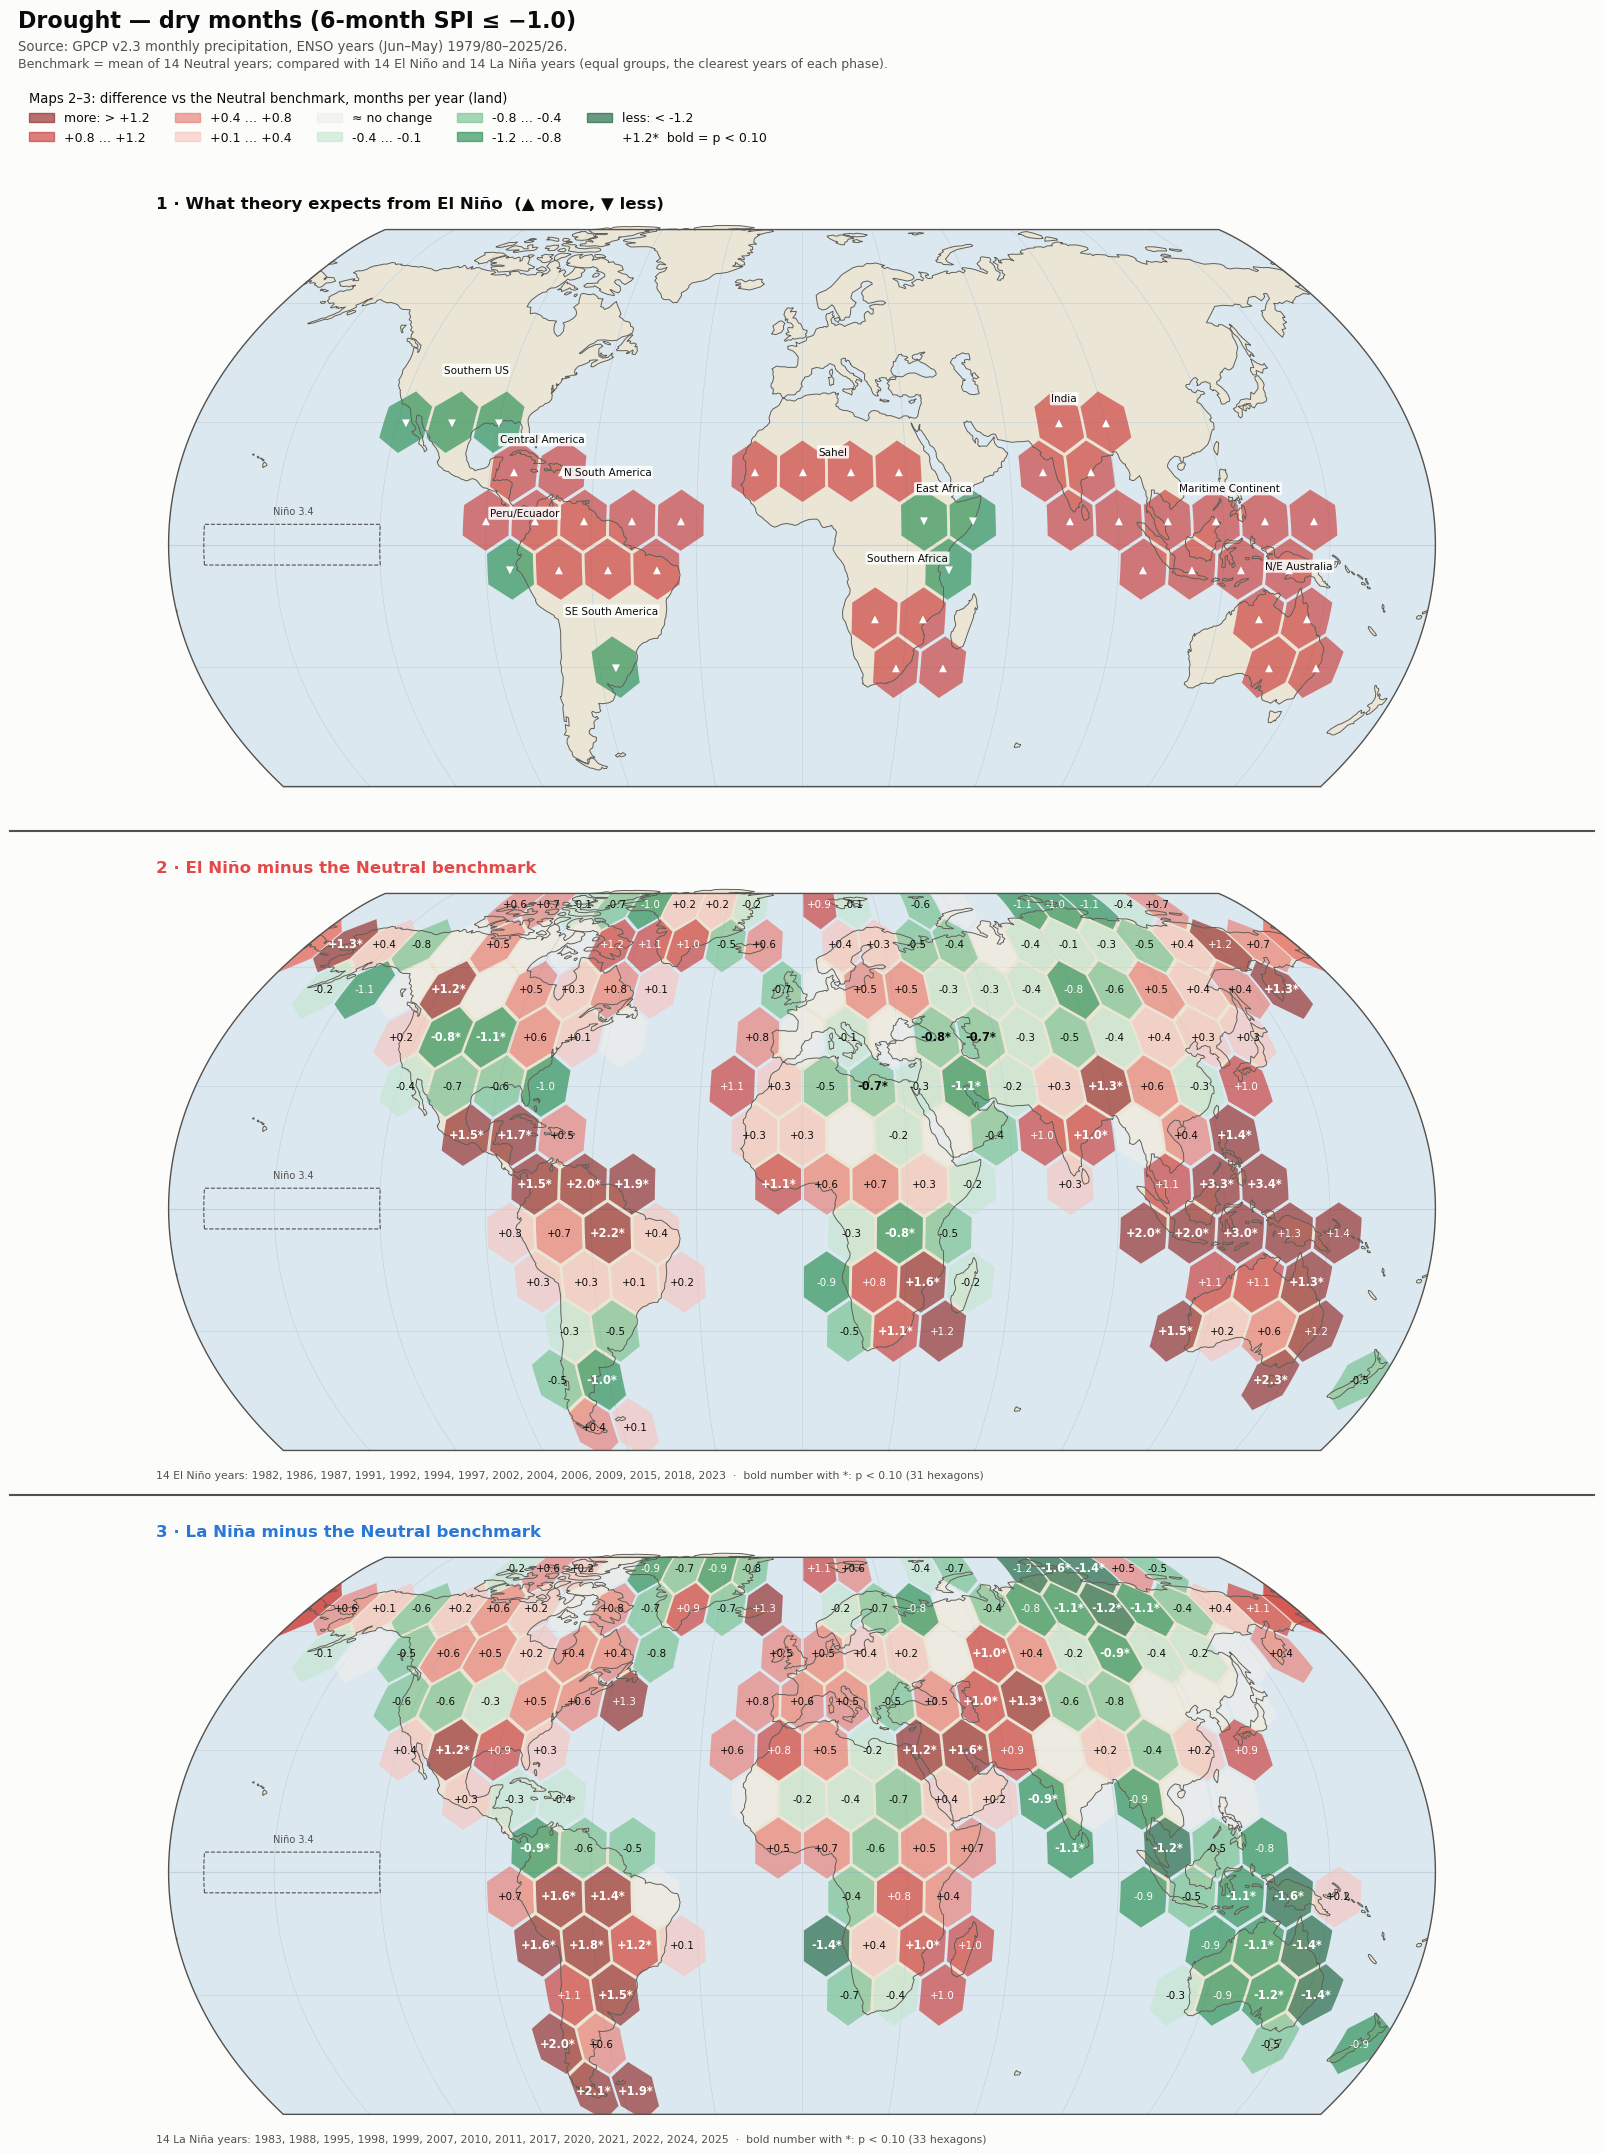

In [25]:
Image(filename="maps/hex_3_drought.png")

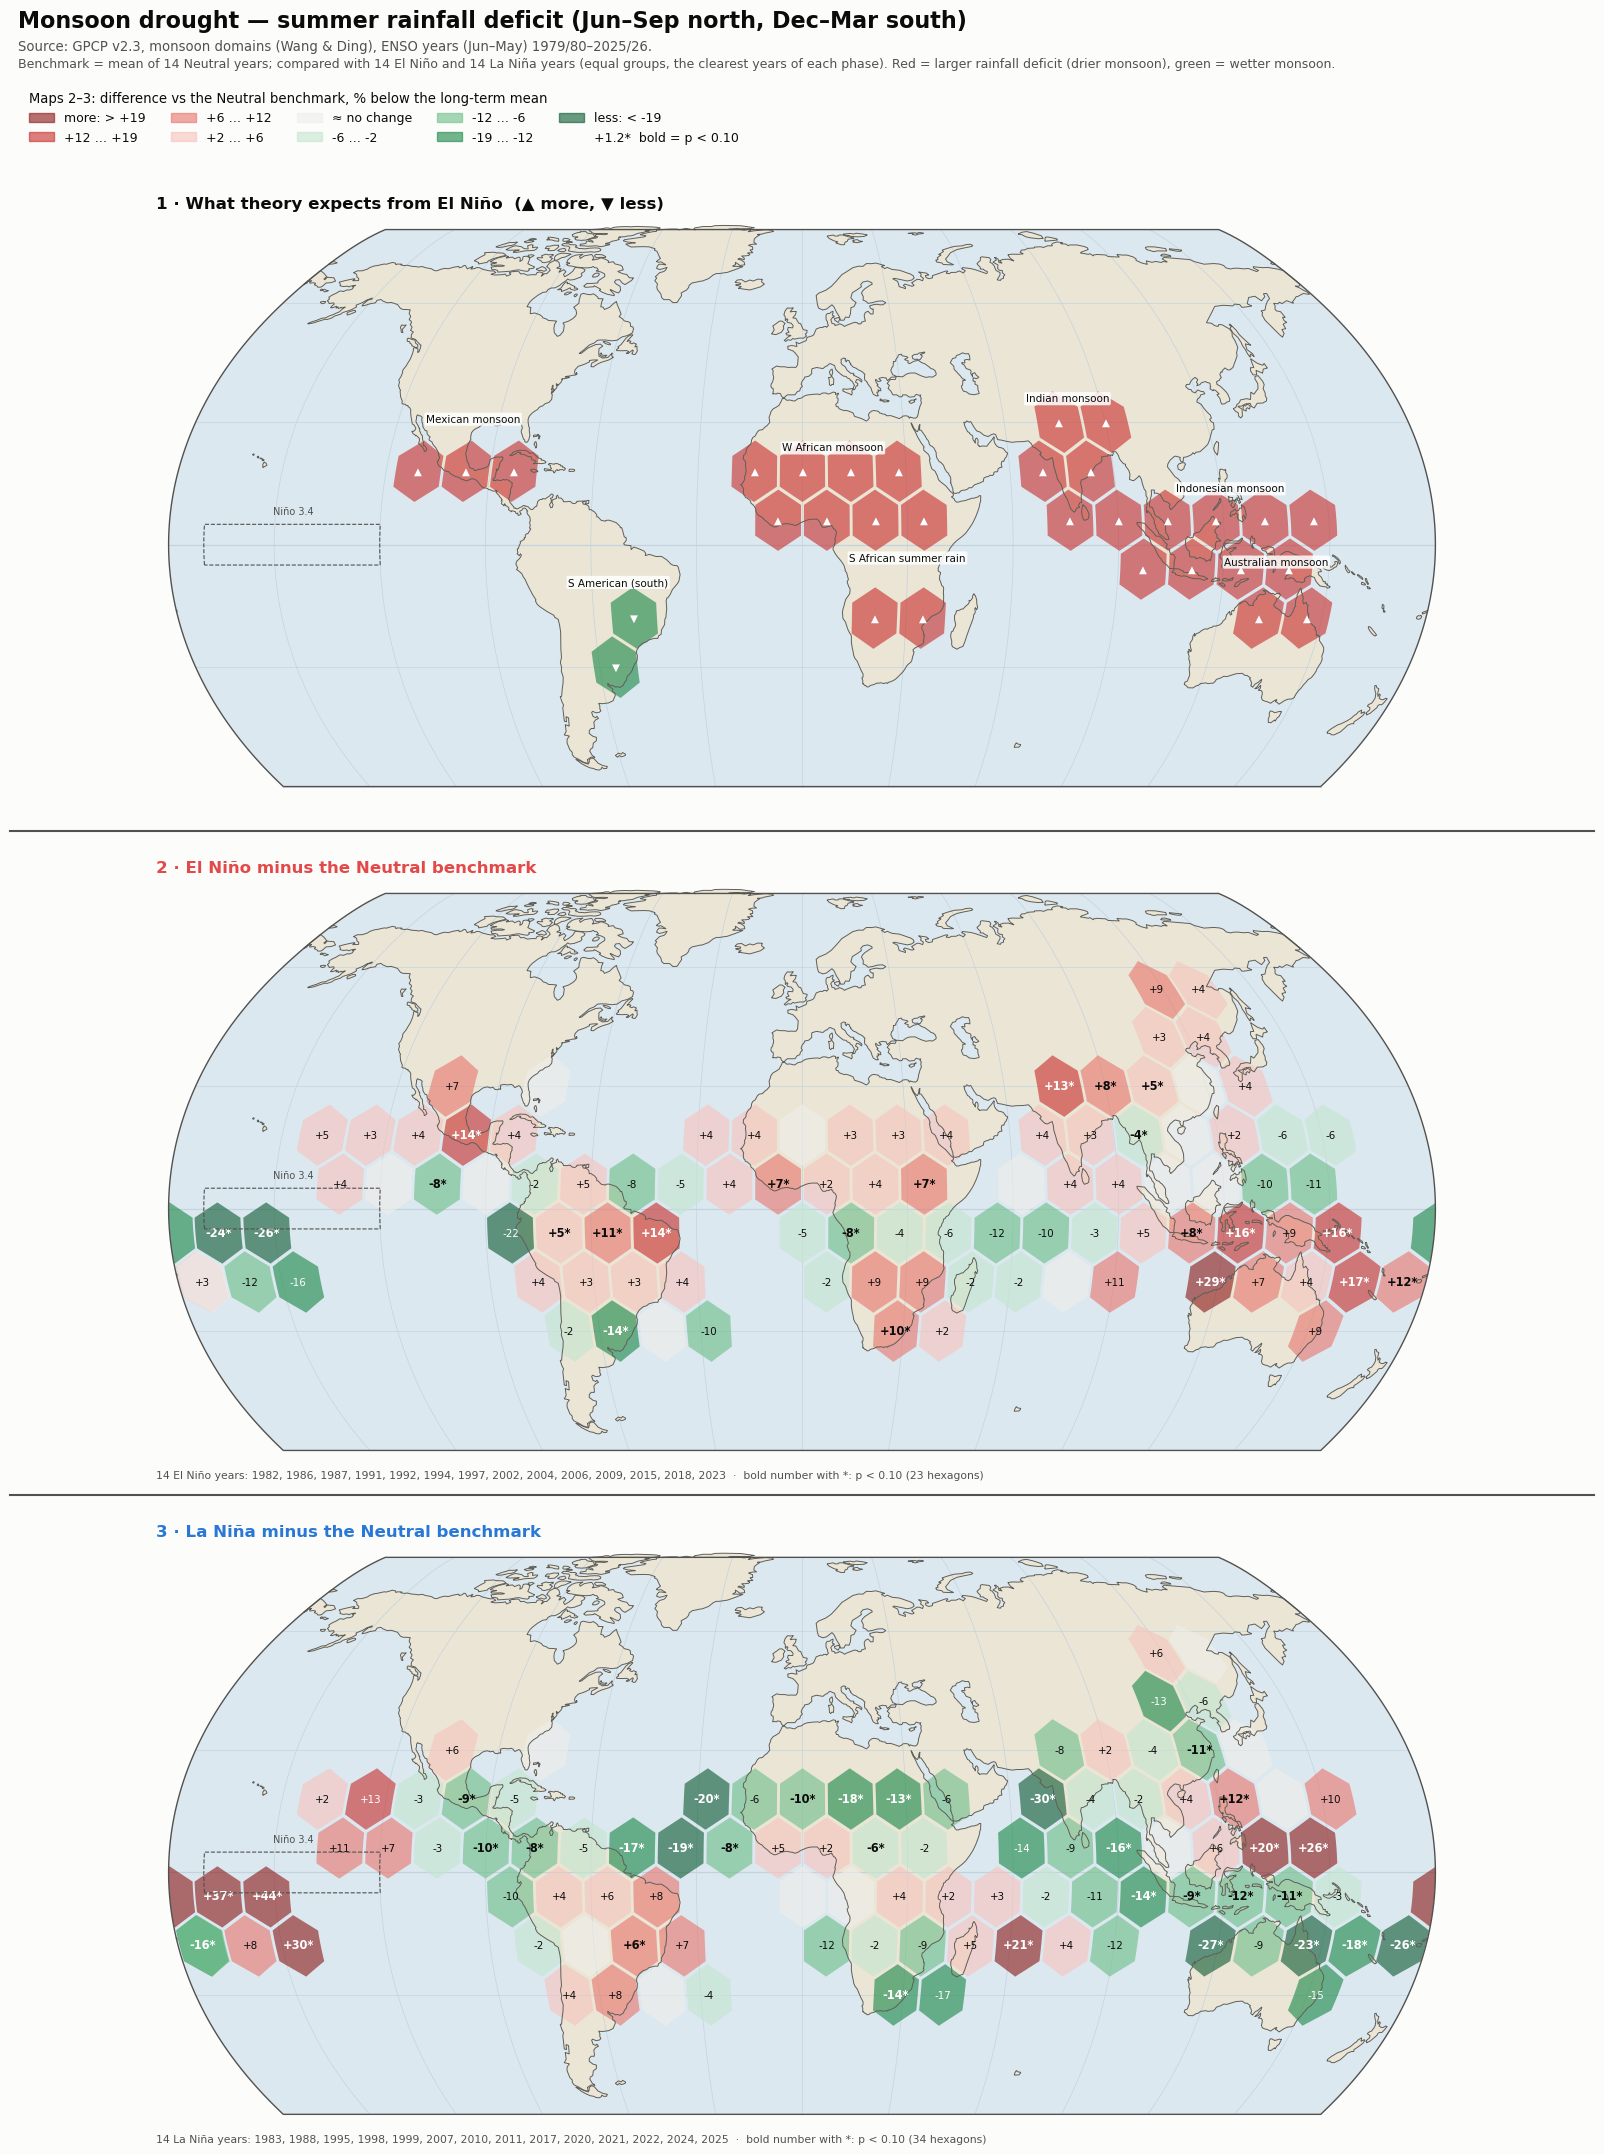

In [26]:
Image(filename="maps/hex_4_monsoon.png")

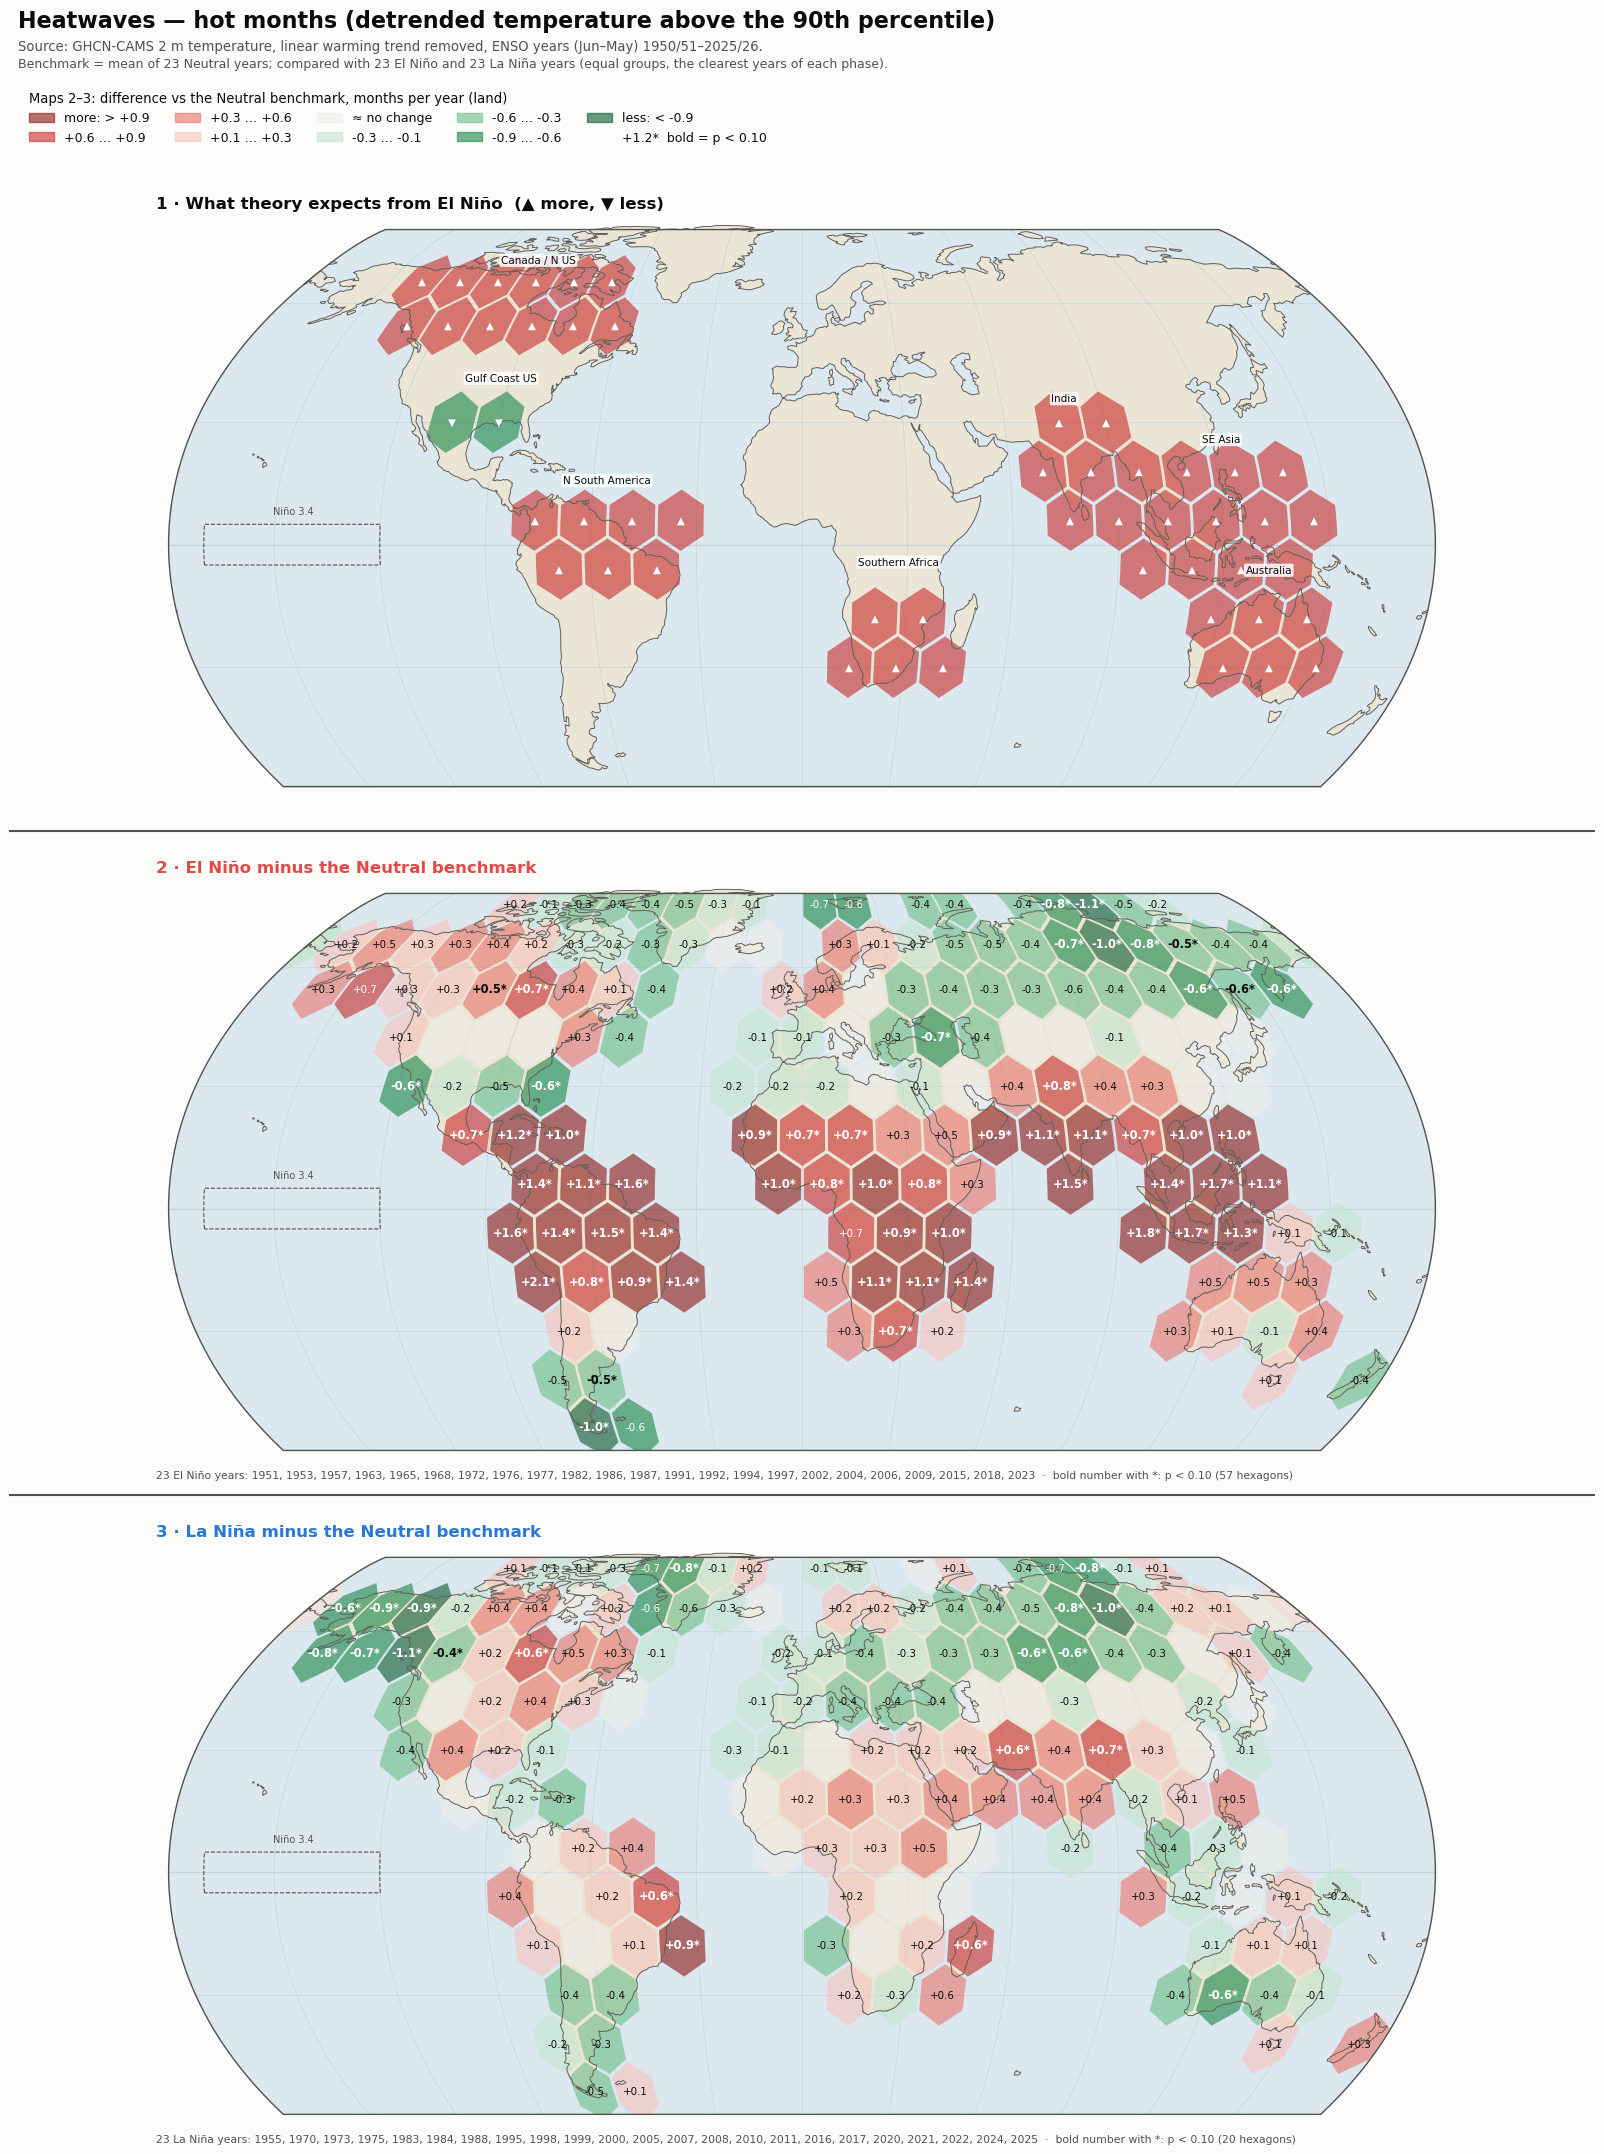

In [27]:
Image(filename="maps/hex_5_heat.png")

---
## Findings in numbers

The measures below have p < 0.1 or an El Niño vs Neutral change of at least 25%,
sorted by the strength of the signal.

In [28]:
t = cmp_.copy()
t["|Δ|"] = t[EN_VS_N].abs()
t = t[(t[P_COL] < 0.1) | (t["|Δ|"] >= 25)]
t[["section", "measure", "source", EN_VS_N, LN_VS_N, P_COL]].sort_values(P_COL).round(2)

,section,measure,source,El Niño vs Neutral [%],La Niña vs Neutral [%],"p (EN vs LN, all years)"
29,Categories (Saffir-Simpson),Typhoons: West Pacific — cat. 3–5,IBTrACS,3.18,-38.10,0.00
31,Typhoons,West Pacific — ACE energy,IBTrACS,10.48,-41.46,0.00
27,Hurricanes,East/Central Pacific — ACE energy,IBTrACS,50.96,-17.09,0.00
22,Categories (Saffir-Simpson),Hurricanes: North Atlantic — cat. 4–5,IBTrACS,0.00,185.71,0.00
21,Categories (Saffir-Simpson),Hurricanes: North Atlantic — cat. 3–5,IBTrACS,-25.00,65.62,0.00
20,Hurricanes,North Atlantic — all storms,IBTrACS,-19.41,24.12,0.00
30,Categories (Saffir-Simpson),Typhoons: West Pacific — cat. 4–5,IBTrACS,19.10,-30.34,0.00
23,Hurricanes,North Atlantic — ACE energy,IBTrACS,-27.59,35.70,0.00
25,Categories (Saffir-Simpson),Hurricanes: East/Central Pacific — cat. 3–5,IBTrACS,48.15,-16.67,0.00
26,Categories (Saffir-Simpson),Hurricanes: East/Central Pacific — cat. 4–5,IBTrACS,93.55,0.00,0.01


### Limitations

* **Few years in GDACS.** 3 cyclone seasons per phase means the direction matters more than the
  exact percentages. IBTrACS (13 per phase) and the long-record hex maps serve as the check.
* **A GDACS event count is not a casualty count.** The alert level depends on exposed population,
  so the same wind over the ocean and over Manila gets a different alert colour.
* **Peru and Ecuador.** The data show fewer floods in El Niño years. But the great "coastal El Niño"
  floods of 2017 fall in the dropped catalogue transition (2016–18), and GDACS does not cover 1997/98.
* **The +12-month outlook** is a scenario, not a certainty. It depends on how fast the Pacific
  swings to La Niña.
* **Heatwaves** are monthly hot extremes (detrended), not daily heatwave days. They show where
  El Niño shifts the odds of a hot month.